---
# 1. Imports & Configurations

In [1]:
## Clones repo into the notebook
!git clone -q https://github.com/KhoaTranGit/UTD-BCU-Machine-Learning.git
!pip install -q catboost optuna umap-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 9.6 MB/s eta 0:00:00


In [2]:
import numpy as np
import pandas as pd
import polars as pl
import polars.selectors as cs
import matplotlib.pyplot as plt
import seaborn as sea
from pathlib import Path

from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
import lightgbm
import xgboost
import catboost
from lightgbm import LGBMClassifier, early_stopping
from xgboost  import XGBClassifier
from catboost import CatBoostClassifier

from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import average_precision_score, confusion_matrix
from sklearn.base import clone
import optuna
import logging
import re
import shap


import sys
sys.path.append("/content/UTD-BCU-Machine-Learning/2026 Projects/LeukoAlert/src")
from evaluate_model import evaluate_model
from plot_umap import plot_umap

In [3]:
## Verifies data path exists
data_path = Path(
    "/content/UTD-BCU-Machine-Learning/"
    "2026 Projects/LeukoAlert/data/"
    "leukoalert_all_cohorts.csv.gz"
)
print(data_path.exists())

True


In [4]:
## Important Configs
SEED = 42

TARGET_MAP = {
    "leukemia":1,
    "healthy":0
}

TARGET_INVMAP = {
    1:"leukemia",
    0:"healthy"
}

---
# 1. Data Loading & Inspection

## 1.1 Loading & Checking Main Data

In [5]:
## Loads data, prints shape, print features' dtypes
data = pl.read_csv(data_path)

print(f"Data's Shape {data.shape}\n")


schema_df = pd.DataFrame({
    "Feature": data.columns,
    "Data Type": [str(dtype) for dtype in data.dtypes]
})

display(
    schema_df.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [
            ("text-align", "left"),
            ("font-weight", "bold")
        ]}
    ])
)

Data's Shape (446663, 81)



Feature,Data Type
row_key,String
sample_id,String
Q-Flag(Blasts/Abn Lympho?),Float64
Q-Flag(Blasts?),Float64
Q-Flag(Abn Lympho?),Float64
Q-Flag(Left Shift?),Float64
Q-Flag(Atypical Lympho?),Float64
Q-Flag(RBC Agglutination?),Float64
Q-Flag(Turbidity/HGB Interf?),Float64
Q-Flag(Iron Deficiency?),Float64


In [6]:
print("Data's Head")
display(data.head())

Data's Head


row_key,sample_id,Q-Flag(Blasts/Abn Lympho?),Q-Flag(Blasts?),Q-Flag(Abn Lympho?),Q-Flag(Left Shift?),Q-Flag(Atypical Lympho?),Q-Flag(RBC Agglutination?),Q-Flag(Turbidity/HGB Interf?),Q-Flag(Iron Deficiency?),Q-Flag(HGB Defect?),Q-Flag(Fragments?),Q-Flag(PLT Clumps?),WBC(10^9/L),RBC(10^12/L),HGB(g/L),HCT(%),MCV(fL),MCH(pg),MCHC(g/L),PLT(10^9/L),RDW-SD(fL),RDW-CV(%),PDW(fL),MPV(fL),P-LCR(%),PCT(%),NRBC#(10^9/L),NRBC%(/100WBC),NEUT#(10^9/L),LYMPH#(10^9/L),MONO#(10^9/L),EO#(10^9/L),BASO#(10^9/L),NEUT%(%),LYMPH%(%),MONO%(%),…,[TNC(10^9/L)],[WBC-N(10^9/L)],[TNC-N(10^9/L)],[BA-N#(10^9/L)],[BA-N%(%)],[WBC-D(10^9/L)],[TNC-D(10^9/L)],[NEUT#&(10^9/L)],[NEUT%&(%)],[LYMP#&(10^9/L)],[LYMP%&(%)],[HFLC#(10^9/L)],[HFLC%(%)],[BA-D#(10^9/L)],[BA-D%(%)],[NE-SSC(ch)],[NE-SFL(ch)],[NE-FSC(ch)],[LY-X(ch)],[LY-Y(ch)],[LY-Z(ch)],[MO-X(ch)],[MO-Y(ch)],[MO-Z(ch)],[NE-WX],[NE-WY],[NE-WZ],[LY-WX],[LY-WY],[LY-WZ],[MO-WX],[MO-WY],leukemia_label,cohort,evaluation_cohort,site,source_file
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str
"""train_site_A:1""","""patient_000001""",300.0,104.253394,70.271493,0.0,300.0,100.0,110.0,70.0,70.0,0.0,300.0,0.18,1.59,68.0,15.9,100.0,42.8,428.0,1.0,48.7,15.4,5.5,10.2,18.2,0.0,0.0,0.0,0.07,0.06,0.03,0.02,0.0,38.9,33.3,16.7,…,0.18,0.18,0.18,0.0,0.0,0.19,0.19,0.07,38.9,0.06,33.3,0.0,0.0,0.0,0.0,151.8,117.2,60.6,76.5,73.9,62.5,130.0,148.5,64.8,217.0,316.0,363.0,392.0,176.0,400.0,123.0,47.0,"""leukemia""","""train""","""train""","""A""","""train_site_A.csv"""
"""train_site_A:2""","""patient_000002""",100.0,104.253394,70.271493,0.0,10.0,70.0,80.0,70.0,70.0,0.0,30.0,42.68,3.29,103.0,31.5,95.7,31.3,327.0,325.0,42.4,12.1,11.7,10.6,29.6,0.34,0.07,0.2,6.68,35.74,0.18,0.0,0.08,15.7,83.7,0.4,…,42.75,42.68,42.75,0.08,0.2,42.2,42.26,6.54,15.4,35.66,83.5,0.08,0.2,0.01,0.0,152.8,53.5,87.7,64.9,47.3,49.4,120.0,98.1,62.8,308.0,673.0,548.0,709.0,1036.0,526.0,250.0,612.0,"""leukemia""","""train""","""train""","""A""","""train_site_A.csv"""
"""train_site_A:3""","""patient_000003""",0.0,104.253394,70.271493,300.0,0.0,70.0,90.0,70.0,60.0,20.0,10.0,2.62,2.23,71.0,21.6,96.9,31.8,329.0,21.0,73.9,21.6,12.486443,10.834967,31.071955,0.194058,0.01,0.4,2.4,0.08,0.13,0.0,0.01,91.5,3.1,5.0,…,2.63,2.62,2.63,0.01,0.4,2.6,2.61,1.92,73.2,0.08,3.1,0.0,0.0,0.0,0.0,154.3,61.6,83.7,88.1,79.6,60.3,121.7,116.7,64.2,402.0,1121.0,633.0,318.0,452.0,332.0,329.0,343.0,"""leukemia""","""train""","""train""","""A""","""train_site_A.csv"""
"""train_site_A:4""","""patient_000004""",10.0,104.253394,70.271493,300.0,0.0,80.0,90.0,70.0,60.0,20.0,0.0,2.61,2.23,72.0,21.9,98.2,32.3,329.0,17.0,74.5,21.5,12.486443,10.834967,31.071955,0.194058,0.0,0.0,2.39,0.07,0.14,0.0,0.01,91.5,2.7,5.4,…,2.61,2.61,2.61,0.01,0.4,2.61,2.61,1.94,74.3,0.07,2.7,0.0,0.0,0.01,0.4,156.4,62.9,85.6,88.3,79.3,63.0,122.8,120.9,66.7,377.0,1224.0,900.0,374.0,114.0,397.0,342.0,513.0,"""leukemia""","""train""","""train""","""A""","""train_site_A.csv"""
"""train_site_A:5""","""patient_000005""",40.0,104.253394,70.271493,10.0,60.0,100.0,110.0,70.0,70.0,20.0,100.0,8.13,2.05,83.0,20.5,100.0,40.5,405.0,129.0,61.2,18.0,11.5,11.3,33.7,0.15,0.01,0.1,4.5,2.1,0.99,0.49,0.05,55.4,25.8,12.2,…,8.14,8.13,8.14,0.05,0.6,8.08,8.09,4.44,54.7,2.05,25.2,0.05,0.6,0.07,0.9,153.4,48.6,90.6,82.0,67.7,57.0,125.1,112.6,63.7,313.0,659.0,585.0,524.0,975.0,526.0,272.0,711.0,"""leukemia""","""train""","""train""","""A""","""train_site_A.csv"""


In [7]:
## No NA counts in data
data.select(
  pl.all().is_null().sum()
).unpivot(
    variable_name="feature",
    value_name="NA_count"
).filter(
    pl.col("NA_count") > 0
)

feature,NA_count
str,u32


In [8]:
## Small duplicate counts
exclude_features = ["row_key", "sample_id", "cohort",
                    "evaluation_cohort", "site", "source_file"]
duplicate_count = (
  data.select(
    pl.exclude(exclude_features)
  ).is_duplicated().sum()
)

print(f"Duplicate Samples: {duplicate_count}")

Duplicate Samples: 31


In [9]:
def clean_col(name: str) -> str:
    name = name.strip().lower()

    name = name.replace("#", "_abs")
    name = name.replace("%", "_pct")
    name = name.replace("&", "_alt")

    name = name.replace("[", "").replace("]", "")
    name = re.sub(r"[^a-z0-9]+", "_", name)
    name = name.strip("_")

    # Eliminate duplicate tokens
    name = re.sub(r"(?:_pct){2,}", "_pct", name)

    return name


data = data.rename({col:clean_col(col) for col in data.columns})

## 1.2 Splitting Train/Val/Test Sets

In [10]:
exclude_metas = ["row_key", "sample_id", "cohort",
                 "source_file", "evaluation_cohort"]

## Gets train set
train = data.filter(pl.col("cohort") == "train").select(pl.exclude(exclude_metas))


## Gets internal validation set (for tuning & model comparison)
val_internal = data.filter(
    pl.col("cohort") == "validation",
    pl.col("evaluation_cohort") == "internal_validation"  ## sites A,B,C
).select(pl.exclude(exclude_metas))


## Gets external validation set (unbiased held-out set for evaluating tuned models)
val_external = data.filter(
    pl.col("cohort") == "validation",
    pl.col("evaluation_cohort") == "external_validation"  ## sites E,D,F,G
).select(pl.exclude(exclude_metas))


## Gets train set
test  = data.filter(pl.col("cohort") == "test").select(pl.exclude(exclude_metas))

## 1.3 Inspecting Class Distributions


*   Train dataset preserves an imbalanced ratio of 1:2 across sites
*   Validation & Test datasets enforce an imbalanced ratio of 1:30 across sites


In [11]:
## Inspect overall target distribution across data splits
display(
    train.group_by("leukemia_label").len().with_columns((pl.col("len")/len(train)).round(2).alias("train_proportion"))
    .sort("leukemia_label")
)

display(
    val_internal.group_by("leukemia_label").len().with_columns((pl.col("len")/len(val_internal)).round(3).alias("val_int_proportion"))
    .sort("leukemia_label")
)

display(
    val_external.group_by("leukemia_label").len().with_columns((pl.col("len")/len(val_external)).round(3).alias("val_external_proportion"))
    .sort("leukemia_label")
)

display(
    test.group_by("leukemia_label").len().with_columns((pl.col("len")/len(test)).round(3).alias("test_proportion"))
    .sort("leukemia_label")
)

leukemia_label,len,train_proportion
str,u32,f64
"""healthy""",17948,0.67
"""leukemia""",8974,0.33


leukemia_label,len,val_int_proportion
str,u32,f64
"""healthy""",203794,0.963
"""leukemia""",7818,0.037


leukemia_label,len,val_external_proportion
str,u32,f64
"""healthy""",143859,0.961
"""leukemia""",5789,0.039


leukemia_label,len,test_proportion
str,u32,f64
"""healthy""",56191,0.961
"""leukemia""",2290,0.039


In [12]:
## Proportions of leukemia labels in across sites train dataset
print("Proportions of Leukemia Labels in Train Dataset across Sites\n")

train.pivot(
    index="leukemia_label",
    on="site",
    values="site",
    aggregate_function="len"
).with_columns(
    pl.exclude("leukemia_label") /
    pl.exclude("leukemia_label").sum()
)

Proportions of Leukemia Labels in Train Dataset across Sites



leukemia_label,A,B,C
str,f64,f64,f64
"""leukemia""",0.333333,0.333333,0.333333
"""healthy""",0.666667,0.666667,0.666667


In [13]:
## Proportions of leukemia labels across sites in internal validation dataset
print("Proportions of Leukemia Labels in Internal Validation Dataset across Sites\n")

val_internal.pivot(
    index="leukemia_label",
    on="site",
    values="site",
    aggregate_function="len"
).with_columns(
    pl.exclude("leukemia_label") /
    pl.exclude("leukemia_label").sum()
)

Proportions of Leukemia Labels in Internal Validation Dataset across Sites



leukemia_label,A,B,C
str,f64,f64,f64
"""healthy""",0.954456,0.981787,0.958635
"""leukemia""",0.045544,0.018213,0.041365


In [14]:
## Proportions of leukemia labels across sites in external validation dataset
print("Proportions of Leukemia Labels in External Validation Dataset across Sites\n")

val_external.pivot(
    index="leukemia_label",
    on="site",
    values="site",
    aggregate_function="len"
).with_columns(
    pl.exclude("leukemia_label") /
    pl.exclude("leukemia_label").sum()
)

Proportions of Leukemia Labels in External Validation Dataset across Sites



leukemia_label,D,E,F,G
str,f64,f64,f64,f64
"""healthy""",0.95611,0.973007,0.950989,0.813365
"""leukemia""",0.04389,0.026993,0.049011,0.186635


In [15]:
## Proportions of leukemia labels across sites in test dataset
print("Proportions of Leukemia Labels in External Validation Dataset across Sites\n")

test.pivot(
    index="leukemia_label",
    on="site",
    values="site",
    aggregate_function="len"
).with_columns(
    pl.exclude("leukemia_label") /
    pl.exclude("leukemia_label").sum()
)

Proportions of Leukemia Labels in External Validation Dataset across Sites



leukemia_label,A_prime
str,f64
"""healthy""",0.960842
"""leukemia""",0.039158


## 1.4 Encoding Target value

In [16]:
train, val_internal, val_external, test = [
  df.with_columns(
    pl.col("leukemia_label").replace_strict(TARGET_MAP, return_dtype=pl.Int64)
  )
  for df in [train, val_internal, val_external, test]
]

---
# 2. EDA

In [17]:
train_pd = train.to_pandas()

pearson_corr  = train_pd.drop(columns=["site"]).corr(method="pearson")
spearman_corr = train_pd.drop(columns=["site"]).corr(method="spearman")

pearson_mask  = np.triu(pearson_corr)
spearman_mask = np.triu(spearman_corr)

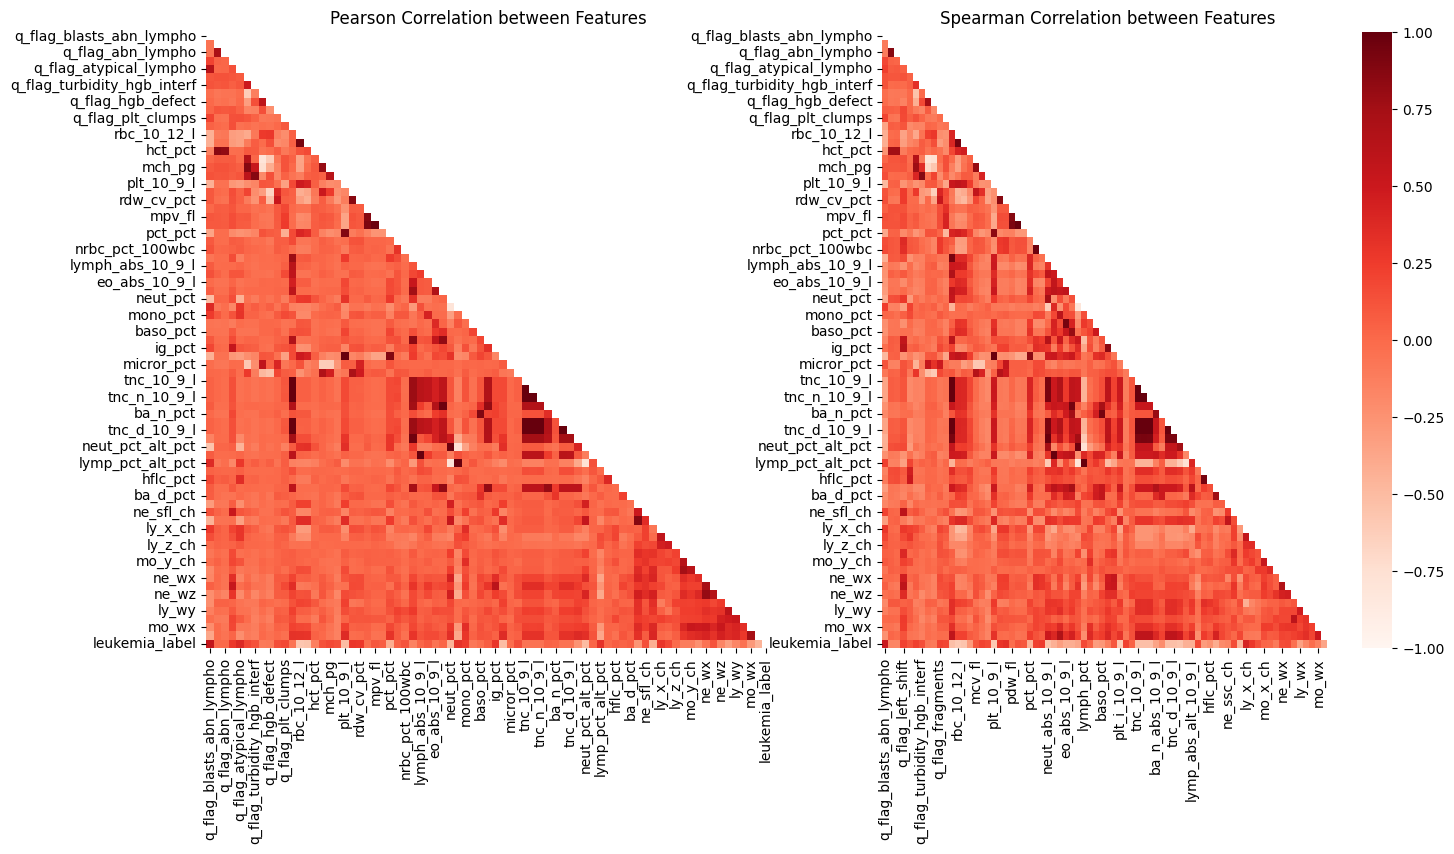

In [18]:
# @title
plt.figure(figsize=(16,8))

plt.subplot(121)
sea.heatmap(pearson_corr, cmap="Reds", mask=pearson_mask, vmin=-1, vmax=1, cbar=False)
plt.title("Pearson Correlation between Features")

plt.subplot(122)
sea.heatmap(spearman_corr, cmap="Reds", mask=spearman_mask, vmin=-1, vmax=1)
plt.title("Spearman Correlation between Features")

plt.show()

In [19]:
## Extract feature-target correlations from spearman & pearson correlation matrices
leukemia_spearman = (
    spearman_corr["leukemia_label"]
    .sort_values(ascending=False)
    .reset_index()
    .rename(columns={"index":"feature"})
    .query("feature != 'leukemia_label'")
)

leukemia_pearson = (
    pearson_corr["leukemia_label"]
    .sort_values(ascending=False)
    .reset_index()
    .rename(columns={"index":"feature"})
    .query("feature != 'leukemia_label'")
)

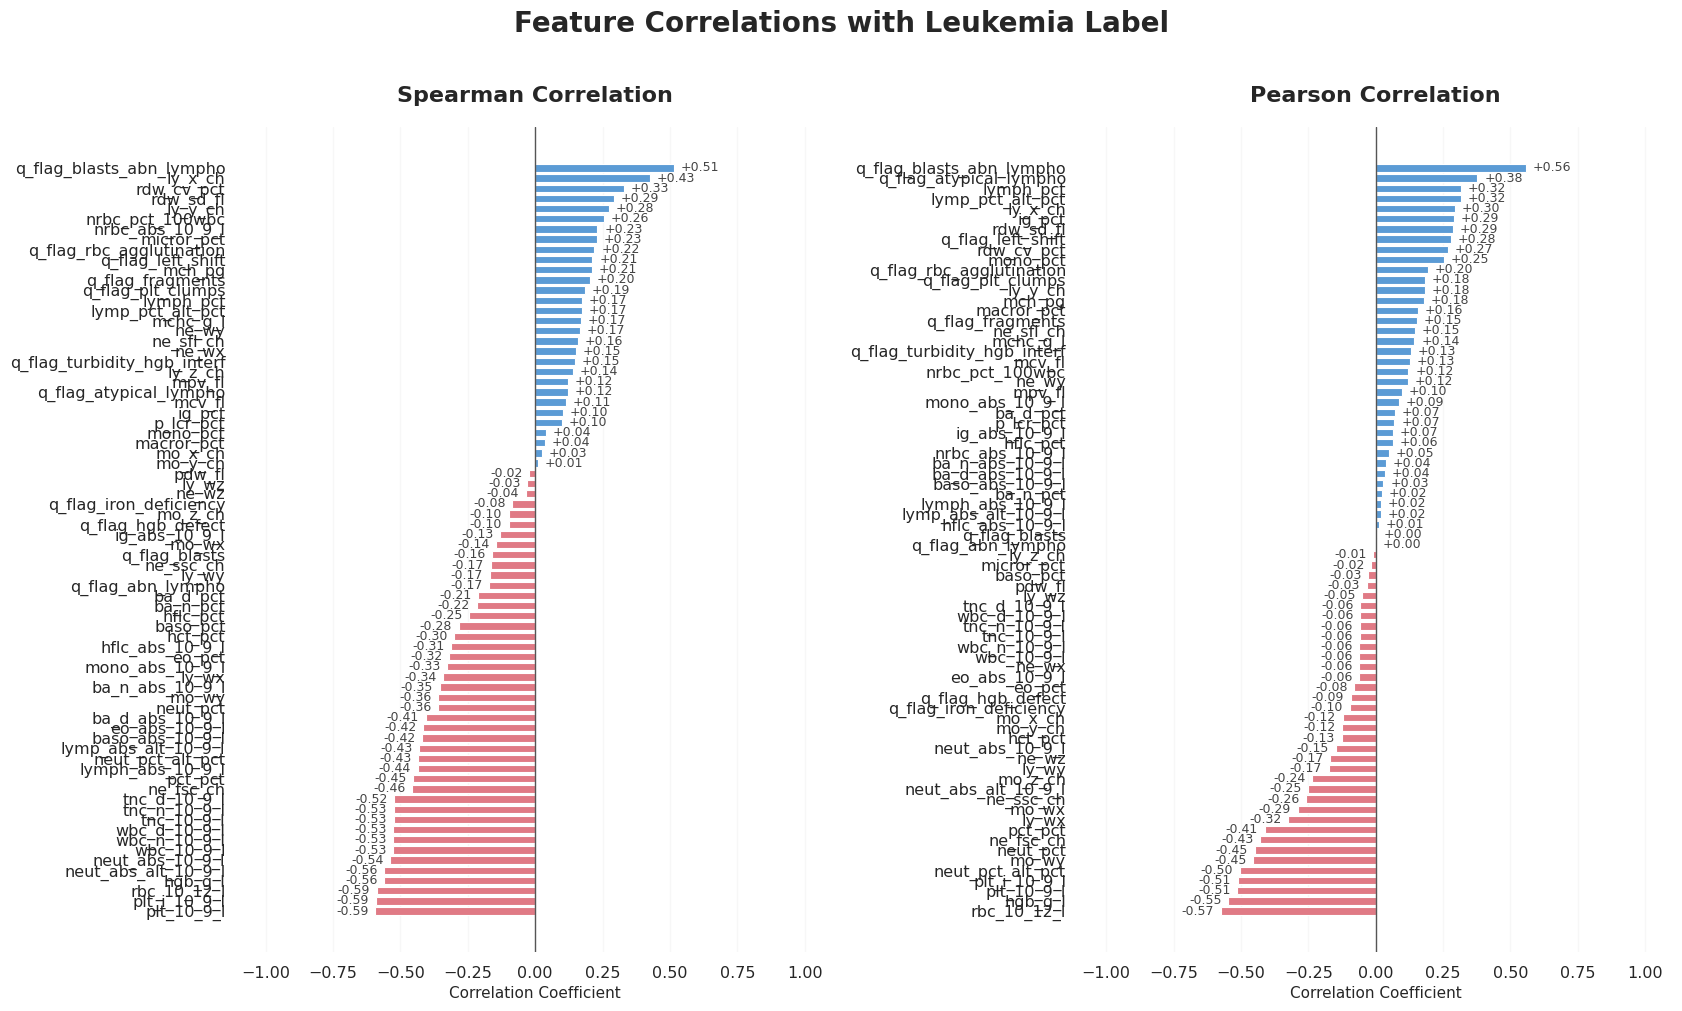

In [20]:
# @title
sea.set_theme(style="white", context="notebook", font_scale=1.05)

fig, axes = plt.subplots(1, 2, figsize=(17, 10), sharex=True)

datasets = [
    (leukemia_spearman, "Spearman Correlation", "leukemia_label"),
    (leukemia_pearson, "Pearson Correlation", "leukemia_label")
]

for ax, (df, title, value_col) in zip(axes, datasets):
    df = df.sort_values(value_col)

    colors = [
        "#E07A85" if value < 0 else "#5B9BD5"
        for value in df[value_col]
    ]

    bars = ax.barh(
        df["feature"],
        df[value_col],
        color=colors,
        height=0.72,
        edgecolor="white",
        linewidth=0.8
    )

    ax.axvline(0, color="#555555", linewidth=1)
    ax.set_xlim(-1.1, 1.1)
    ax.set_title(title, fontsize=16, fontweight="bold", pad=18)
    ax.set_xlabel("Correlation Coefficient", fontsize=11)
    ax.set_ylabel("")

    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)

    for bar, value in zip(bars, df[value_col]):
        ax.text(
            value + (0.025 if value >= 0 else -0.025),
            bar.get_y() + bar.get_height() / 2,
            f"{value:+.2f}",
            va="center",
            ha="left" if value >= 0 else "right",
            fontsize=9,
            color="#444444"
        )

    sea.despine(ax=ax, left=True, bottom=True)

fig.suptitle(
    "Feature Correlations with Leukemia Label",
    fontsize=20,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

In [21]:
X = train.select(pl.exclude(["leukemia_label", "site"])).to_pandas()
y = train["leukemia_label"].to_pandas()

mutual_info_scores = mutual_info_classif(X, y, random_state=SEED)
mi_df = (
    pd.DataFrame({
        "feature": X.columns,
        "mutual_information": mutual_info_scores
    })
    .sort_values("mutual_information", ascending=True)
)

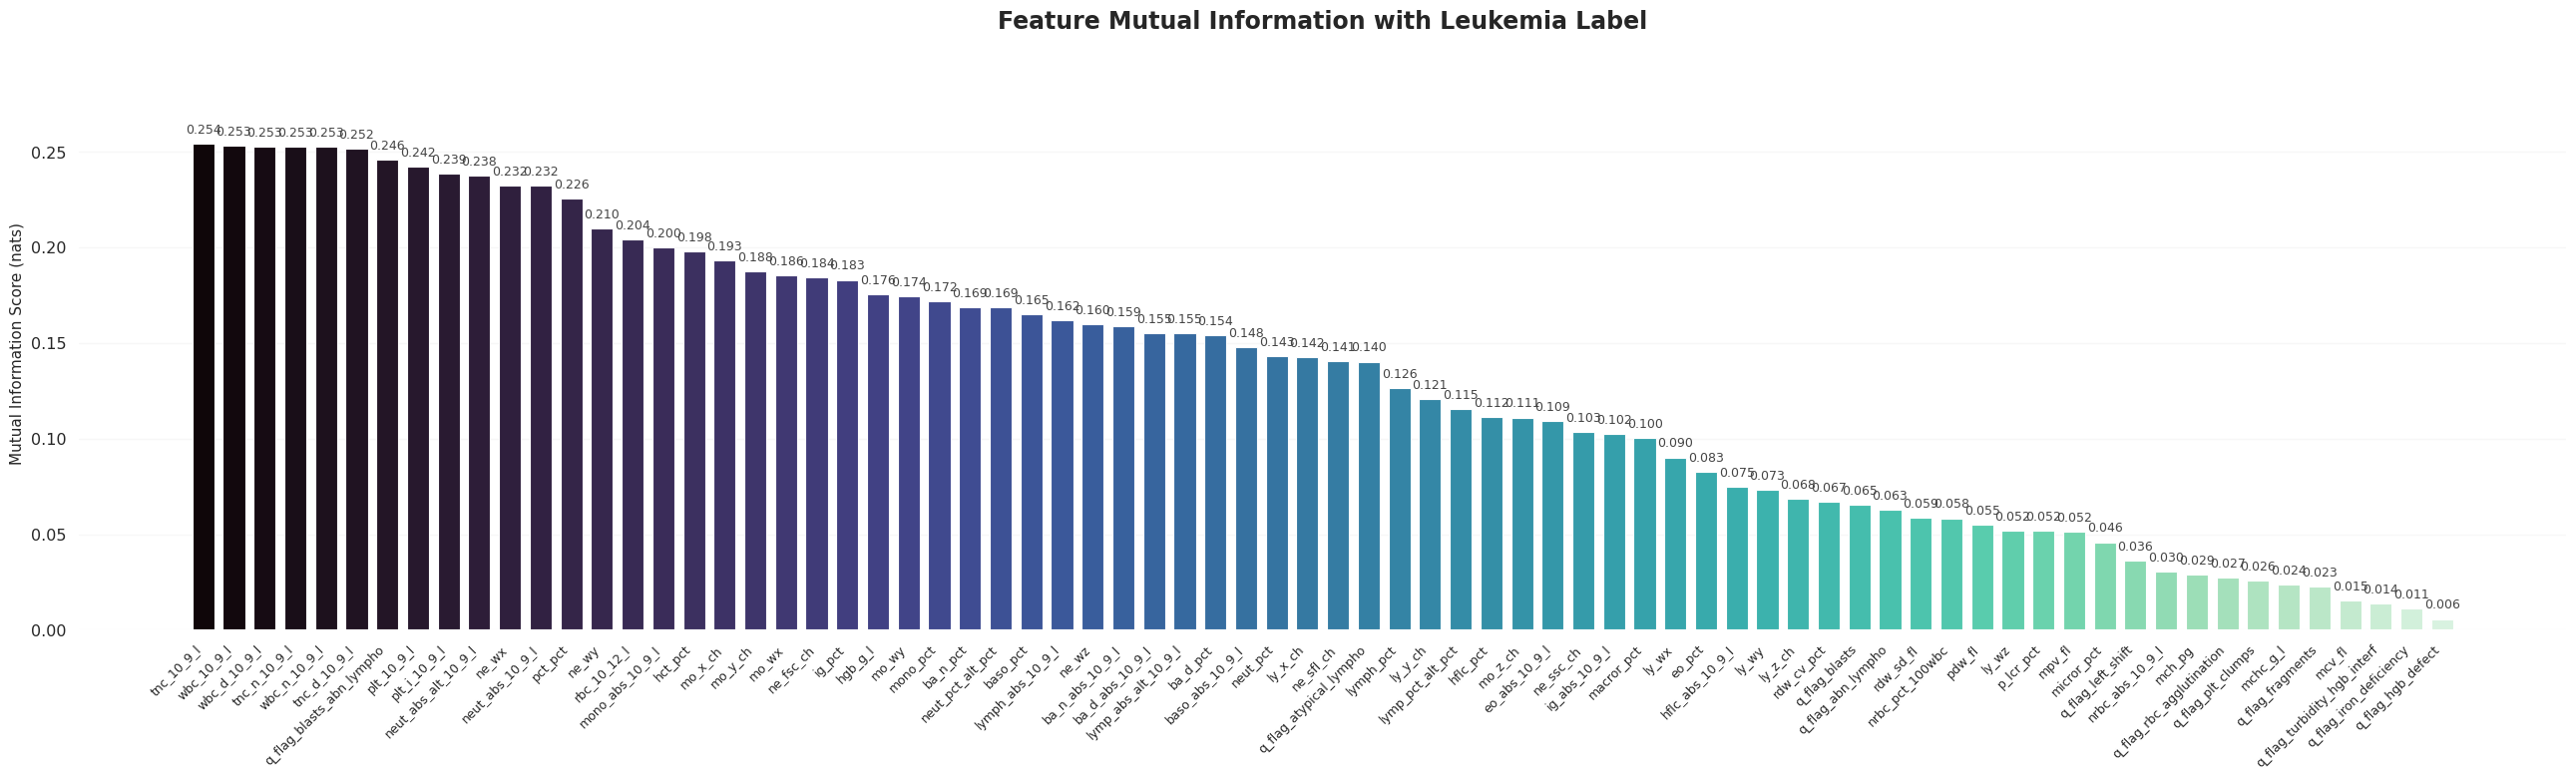

In [22]:
# @title
sea.set_theme(style="white", context="notebook", font_scale=1.05)

fig, ax = plt.subplots(figsize=(26, 8))

# Sort from highest to lowest
mi_plot = mi_df.sort_values("mutual_information", ascending=False)

colors = sea.color_palette("mako", n_colors=len(mi_plot))

bars = ax.bar(
    mi_plot["feature"],
    mi_plot["mutual_information"],
    color=colors,
    width=0.72,
    edgecolor="white",
    linewidth=0.8
)

# Add values above bars
for bar, value in zip(bars, mi_plot["mutual_information"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + max(mi_plot["mutual_information"].max() * 0.015, 0.002),
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=9,
        color="#444444"
    )

ax.set_ylim(0, max(mi_plot["mutual_information"].max() * 1.18, 0.1))

ax.set_title(
    "Feature Mutual Information with Leukemia Label",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("")
ax.set_ylabel("Mutual Information Score (nats)", fontsize=11)

# Rotate feature names to prevent overlap
plt.xticks(rotation=45, ha="right", fontsize=9)

ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

sea.despine(ax=ax, left=True, bottom=True)

plt.tight_layout()
plt.show()

In [23]:
display(mi_df.tail(5))
display(mi_df.head(5))

,feature,mutual_information
43,wbc_n_10_9_l,0.252616
44,tnc_n_10_9_l,0.252874
47,wbc_d_10_9_l,0.252963
11,wbc_10_9_l,0.253400
42,tnc_10_9_l,0.254203


,feature,mutual_information
8,q_flag_hgb_defect,0.005659
7,q_flag_iron_deficiency,0.011308
6,q_flag_turbidity_hgb_interf,0.013759
15,mcv_fl,0.015342
9,q_flag_fragments,0.022618


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


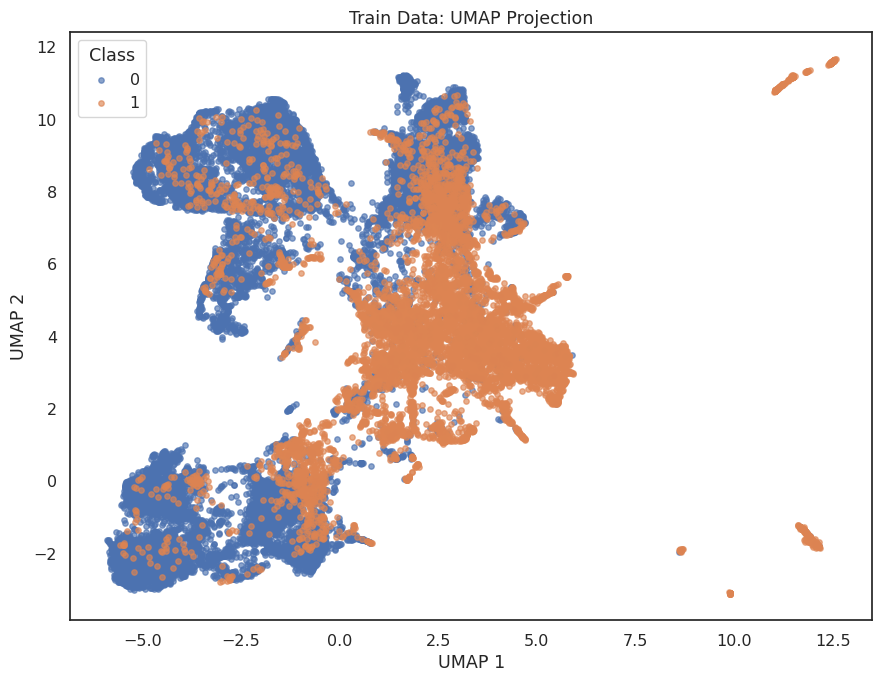

In [24]:
# @title
X = train.select(pl.exclude(["leukemia_label", "site"])).to_pandas()
y = train["leukemia_label"].to_pandas()

train_embedding = plot_umap(
    X,
    y,
    n_neighbors=20,
    min_dist=0.1,
    metric="euclidean",
    scale=True,
    random_state=SEED,
    figsize=(9, 7),
    title="Train Data: UMAP Projection"
)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


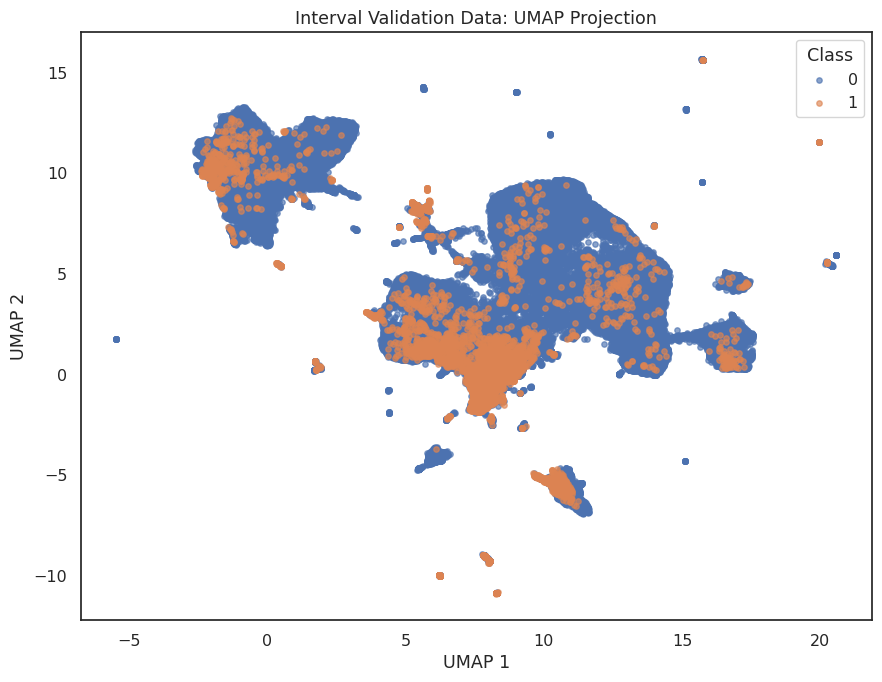

In [25]:
# @title
X = val_internal.select(pl.exclude(["leukemia_label", "site"])).to_pandas()
y = val_internal["leukemia_label"].to_pandas()

val_int_embedding = plot_umap(
    X,
    y,
    n_neighbors=20,
    min_dist=0.1,
    metric="euclidean",
    scale=True,
    random_state=SEED,
    figsize=(9, 7),
    title="Interval Validation Data: UMAP Projection"
)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


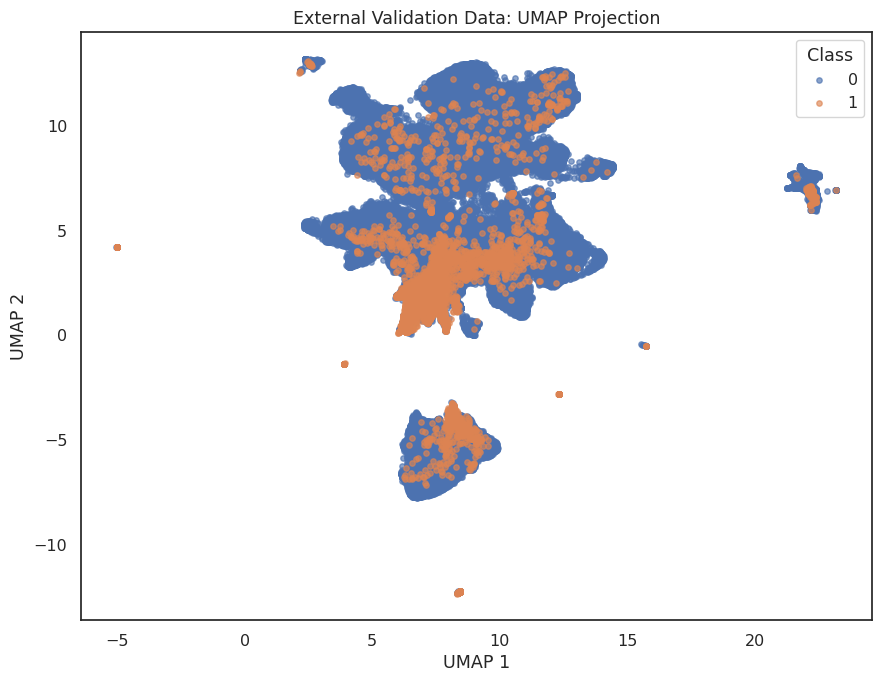

In [26]:
# @title
X = val_external.select(pl.exclude(["leukemia_label", "site"])).to_pandas()
y = val_external["leukemia_label"].to_pandas()

val_ext_embedding = plot_umap(
    X,
    y,
    n_neighbors=20,
    min_dist=0.1,
    metric="euclidean",
    scale=True,
    random_state=SEED,
    figsize=(9, 7),
    title="External Validation Data: UMAP Projection"
)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


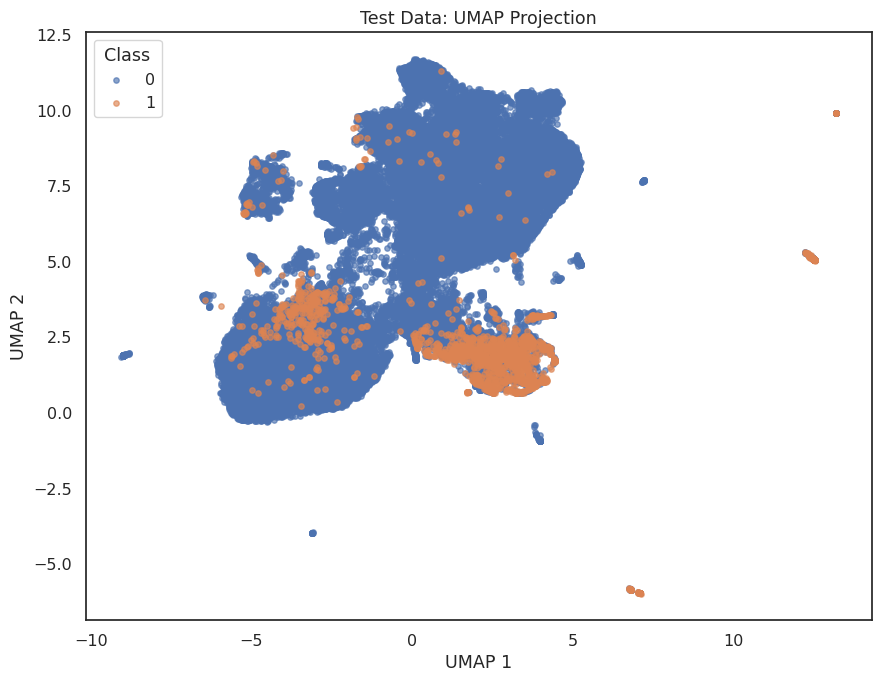

In [27]:
# @title
X = test.select(pl.exclude(["leukemia_label", "site"])).to_pandas()
y = test["leukemia_label"].to_pandas()

test_embedding = plot_umap(
    X,
    y,
    n_neighbors=20,
    min_dist=0.1,
    metric="euclidean",
    scale=True,
    random_state=SEED,
    figsize=(9, 7),
    title="Test Data: UMAP Projection"
)

---
# 3. Baseline Models

## 3.1 Training Baseline Models

In [28]:
models = {
    "RandomForest": RandomForestClassifier(
        n_estimators=300,
        random_state=SEED,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingClassifier(
        random_state=SEED
    ),

    "LightGBM": LGBMClassifier(
        metric='average_precision',
        random_state=SEED,
        verbose=-1,
        n_jobs=-1,
    ),

    "XGBoost": XGBClassifier(
        eval_metric="aucpr",
        random_state=SEED,
        verbosity=0,
        n_jobs=-1
    ),

    "CatBoost": CatBoostClassifier(
        eval_metric="PRAUC",
        random_seed=SEED,
        verbose=False,
        thread_count=-1,
        allow_writing_files=False
    )
}

In [29]:
def get_XY(df):
  df   = df.to_pandas()
  X, y = df.drop(columns=["leukemia_label", "site"]), df["leukemia_label"]
  return X, y

datasets = {}
for dataset,name in [[train,"train"], [val_internal,"val_int"], [val_external,"val_ext"], [test,"test"]]:
  X, y = get_XY(dataset)
  datasets[name] = {"X":X, "y":y}

In [30]:
# results = []

# X_train = datasets["train"]["X"]
# y_train = datasets["train"]["y"]

# for name, model in models.items():
#     print(f"\nTraining {name}...")

#     # Fit only on training data
#     model.fit(X_train, y_train)

#     scores = {"Model": name}

#     for split in ["val_int", "val_ext", "test"]:
#         X = datasets[split]["X"]
#         y = datasets[split]["y"]

#         # Probability of leukemia (positive class = 1)
#         y_prob = model.predict_proba(X)[:, 1]
#         ap = average_precision_score(y, y_prob)

#         scores[split] = ap
#         print(f"  {split}: AP = {ap:.4f}")

#     results.append(scores)

# # Summary table
# results_df = (
#     pd.DataFrame(results)
#     .set_index("Model")
#     .sort_values("val_int", ascending=False)
# )

# print("\nAverage Precision Summary:")
# print(results_df.round(4).to_string())

## 3.2 Optimizing Baseline Models

In [31]:
# Prepare features and labels
X_train = datasets["train"]["X"]
y_train = datasets["train"]["y"]
X_val   = datasets["val_int"]["X"]
y_val   = datasets["val_int"]["y"]

#### 3.2.1 Tuning RandomForestClassifier

In [32]:
# @title
# def objective(trial):
#     params = {
#         ## Constants
#         "random_state": SEED,
#         "n_jobs": -1,
#         ## Params
#         "n_estimators": trial.suggest_int("n_estimators", 100, 500),
#         "max_depth": trial.suggest_int("max_depth", 2, 9),
#         "min_samples_split": trial.suggest_int("min_samples_split", 2, 200),
#         "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 100),
#         "max_features":trial.suggest_float("max_features", 0.5, 1.0)
#     }
#     # Initialize and fit the model
#     model = RandomForestClassifier(**params)
#     model.fit(X_train, y_train)

#     # Predict probabilities on internal validation set
#     y_prob = model.predict_proba(X_val)[:, 1]
#     # Calculate Average Precision score
#     score = average_precision_score(y_val, y_prob)
#     return score

# # Create and run the study
# study = optuna.create_study(direction="maximize",
#                             sampler=optuna.samplers.TPESampler(seed=SEED))
# study.optimize(objective, n_trials=100)

# print("RandomForestClassifier Best Trial:")
# print(f"  Value: {study.best_trial.value:.4f}")
# print("  Params: ")
# for key, value in study.best_trial.params.items():
#     print(f"    {key}: {value}")

In [33]:
rf_params = {
  ## Constants
  "random_state": SEED,
  "n_jobs": -1,
  ## Params
  "n_estimators": 364,
  "max_depth": 9,
  "min_samples_split":37,
  "min_samples_leaf": 22,
  "max_features":0.5402165506053076
}

#### 3.2.2 Tuning HistGradientBoostingClassifier

In [34]:
# @title
# def objective(trial):
#     params = {
#         ## Constants
#         "random_state": SEED,
#         ## Params
#         "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
#         "max_iter": trial.suggest_int("max_iter", 100, 500),
#         "max_depth": trial.suggest_int("max_depth", 2, 12),
#         "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 200),
#         "max_features":trial.suggest_float("max_features", 0.5, 1.0),
#         "l2_regularization": trial.suggest_float("l2_regularization", 1e-8, 10.0, log=True)
#     }
#     # Initialize and fit the model
#     model = HistGradientBoostingClassifier(**params)
#     model.fit(X_train, y_train)

#     # Predict probabilities on internal validation set
#     y_prob = model.predict_proba(X_val)[:, 1]
#     # Calculate Average Precision score
#     score = average_precision_score(y_val, y_prob)
#     return score

# # Create and run the study
# study = optuna.create_study(direction="maximize",
#                             sampler=optuna.samplers.TPESampler(seed=SEED))
# study.optimize(objective, n_trials=100)

# print("HistGradientBoosting Classifier Best Trial:")
# print(f"  Value: {study.best_trial.value:.4f}")
# print("  Params: ")
# for key, value in study.best_trial.params.items():
#     print(f"    {key}: {value}")

In [35]:
histgb_params = {
    ## Constants
    "random_state": SEED,

    ## Optimized hyperparameters
    "learning_rate": 0.006764063066785397,
    "max_iter": 478,
    "max_depth": 5,
    "min_samples_leaf": 77,
    "max_features": 0.5226735720450432,
    "l2_regularization": 3.693047547433555
}

#### 3.2.3 Tuning LGBMClassifier

In [36]:
# @title
# def objective(trial):
#     params = {
#         ## Constants
#         "metric": "average_precision",
#         "random_state": SEED,
#         "verbosity": -1,
#         "n_jobs": -1,
#         "n_estimators": 10000,
#         ## Params
#         "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
#         "max_depth": trial.suggest_int("max_depth", 2, 12),
#         "min_child_samples": trial.suggest_int("min_child_samples", 10, 300),
#         "subsample_freq":trial.suggest_int("subsample_freq", 1, 20),
#         "subsample": trial.suggest_float("subsample", 0.5, 1.0),
#         "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
#         "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
#         "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True)
#     }
#     params["num_leaves"] = trial.suggest_int("num_leaves", 4, min(512, 2**params["max_depth"]))
#     # Initialize and fit the model
#     model = LGBMClassifier(**params)
#     model.fit(X_train, y_train,
#               eval_set=[(X_val, y_val)],
#               eval_metric="average_precision",
#               callbacks=[early_stopping(stopping_rounds=100, verbose=False)])

#     # Predict probabilities on internal validation set
#     y_prob = model.predict_proba(X_val)[:, 1]
#     # Calculate Average Precision score
#     score = average_precision_score(y_val, y_prob)
#     return score

# # Create and run the study
# study = optuna.create_study(direction="maximize",
#                             sampler=optuna.samplers.TPESampler(seed=SEED))
# study.optimize(objective, n_trials=100)

# print("LGBMClassifier Best Trial:")
# print(f"  Value: {study.best_trial.value:.4f}")
# print("  Params: ")
# for key, value in study.best_trial.params.items():
#     print(f"    {key}: {value}")

In [37]:
lgbm_params = {
    ## Constants
    #"metric": "average_precision",
    "random_state": SEED,
    "verbosity": -1,
    "n_jobs": -1,
    "n_estimators": 85,

    ## Optimized hyperparameters
    "learning_rate": 0.022391637805027266,
    "max_depth": 12,
    "min_child_samples": 22,
    "subsample_freq": 14,
    "subsample": 0.5184855697652336,
    "colsample_bytree": 0.7048956867789798,
    "reg_alpha": 1.751082593462855e-06,
    "reg_lambda": 0.05392466911928448,
    "num_leaves": 448
}

In [38]:
# model = LGBMClassifier(**lgbm_params)
# model.fit(X_train, y_train,
#           eval_set=[(X_val, y_val)],
#           eval_metric="average_precision",
#           callbacks=[early_stopping(stopping_rounds=100, verbose=False)])
# print(model.best_iteration_)

#### 3.2.4 Tuning XGBClassifier

In [39]:
# @title
# def objective(trial):
#     params = {
#         ## Constants
#         "random_state": SEED,
#         "eval_metric": "aucpr",
#         "verbosity": 0,
#         "n_jobs": -1,
#         "n_estimators": 10000,
#         ## Params
#         "grow_policy":trial.suggest_categorical("grow_policy", ["depthwise", "lossguide"]),
#         "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
#         "min_child_weight": trial.suggest_float("min_child_weight", 1e-8, 100.0, log=True),
#         "subsample": trial.suggest_float("subsample", 0.5, 1.0),
#         "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
#         "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
#         "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
#         "gamma": trial.suggest_float("gamma", 1e-8, 1.0, log=True)
#     }
#     if params["grow_policy"] == "depthwise":
#         params["max_depth"] = trial.suggest_int("max_depth", 2, 12)
#     else:
#         params["max_depth"] = 0
#         params["max_leaves"] = trial.suggest_int("max_leaves", 4, 256, log=True)

#     # Initialize the model
#     model = XGBClassifier(**params, early_stopping_rounds=100)

#     # Fit the model with early stopping on validation dataset
#     model.fit(
#         X_train, y_train,
#         eval_set=[(X_val, y_val)],
#         verbose=False
#     )

#     # Predict probabilities on internal validation set
#     y_prob = model.predict_proba(X_val)[:, 1]
#     # Calculate Average Precision score
#     score = average_precision_score(y_val, y_prob)
#     return score

# # Create and run the study
# study = optuna.create_study(direction="maximize",
#                             sampler=optuna.samplers.TPESampler(seed=SEED))
# study.optimize(objective, n_trials=100)

# print("XGBClassifier Best Trial:")
# print(f"  Value: {study.best_trial.value:.4f}")
# print("  Params: ")
# for key, value in study.best_trial.params.items():
#     print(f"    {key}: {value}")

In [40]:
xgb_params = {
    ## Constants
    "random_state": SEED,
    #"eval_metric": "aucpr",
    "verbosity": 0,
    "n_jobs": -1,
    "n_estimators": 878,

    ## Optimized hyperparameters
    "grow_policy": "depthwise",
    "learning_rate": 0.0370741662278796,
    "min_child_weight": 9.408768204956597e-08,
    "subsample": 0.5175892595091047,
    "colsample_bytree": 0.7905346057276204,
    "reg_alpha": 9.509180830004382e-07,
    "reg_lambda": 0.02220487406782116,
    "gamma": 1.1827967080615169e-05,
    "max_depth": 12
}

In [41]:
# model = XGBClassifier(**xgb_params, early_stopping_rounds=100)
# model.fit(X_train, y_train,
#           eval_set=[(X_val, y_val)],
#           verbose=False)
# print(model.best_iteration + 1)

#### 3.2.5 Tuning CatBoostClassifier

In [42]:
# @title
# def objective(trial):
#     params = {
#         ## Constants
#         "random_seed": SEED,
#         "eval_metric": "PRAUC",
#         "verbose": False,
#         "thread_count": -1,
#         "allow_writing_files": False,
#         "iterations": 10000,
#         "bootstrap_type": "Bayesian",
#         ## Params
#         "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
#         "depth": trial.suggest_int("depth", 2, 10),
#         "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1e-8, 10.0, log=True),
#         "random_strength": trial.suggest_float("random_strength", 1e-8, 10.0, log=True),
#         "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 1.0),
#         "rsm":trial.suggest_float("rsm", .5, 1.0),
#         "border_count": trial.suggest_int("border_count", 32, 255)
#     }

#     # Initialize the model
#     model = CatBoostClassifier(**params)

#     # Fit the model with early stopping
#     model.fit(
#         X_train, y_train,
#         eval_set=(X_val, y_val),
#         early_stopping_rounds=100,
#         verbose=False
#     )

#     # Predict probabilities on internal validation set
#     y_prob = model.predict_proba(X_val)[:, 1]
#     # Calculate Average Precision score
#     score = average_precision_score(y_val, y_prob)
#     return score

# # Create and run the study
# study = optuna.create_study(direction="maximize",
#                             sampler=optuna.samplers.TPESampler(seed=SEED))
# study.optimize(objective, n_trials=100)

# print("CatBoostClassifier Best Trial:")
# print(f"  Value: {study.best_trial.value:.4f}")
# print("  Params: ")
# for key, value in study.best_trial.params.items():
#     print(f"    {key}: {value}")

In [43]:
catboost_params = {
    ## Constants
    "random_seed": SEED,
    #"eval_metric": "PRAUC",
    "verbose": False,
    "thread_count": -1,
    "allow_writing_files": False,
    "iterations": 564,
    "bootstrap_type": "Bayesian",

    ## Optimized hyperparameters
    "learning_rate": 0.01676726864765657,
    "depth": 10,
    "l2_leaf_reg": 8.801622580284043,
    "random_strength": 9.93584384028874,
    "bagging_temperature": 0.13121632284419055,
    "rsm": 0.8001773914839359,
    "border_count": 237
}

In [44]:
# model = CatBoostClassifier(**catboost_params)
# model.fit(X_train, y_train,
#           eval_set=(X_val, y_val),
#           early_stopping_rounds=100,
#           verbose=False)
# print(model.best_iteration_ + 1)

---
# 4. Evaluating Tuned Baseline Models

In [45]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)
from sklearn.base import clone

def evaluate_model(model, datasets, threshold=0.5):
    """
    Evaluate a trained binary classifier across internal validation,
    external validation, and test datasets.

    Computes Average Precision, ROC-AUC, Precision, Recall, F1,
    Balanced Accuracy, and positive-class prevalence.

    Parameters
    ----------
    model : classifier
        Trained model supporting predict_proba().
    datasets : dict
        Dictionary containing X and y for each dataset split.
    threshold : float, default=0.5
        Probability cutoff for predicting the positive class.

    Returns
    -------
    pd.DataFrame
        Evaluation metrics for each dataset split.
    """
    results = []

    X_train, y_train = datasets["train"]["X"], datasets["train"]["y"]
    cloned_model = clone(model)
    cloned_model.fit(X_train, y_train)

    for data_split in ["val_int", "val_ext", "test"]:
        X = datasets[data_split]["X"]
        y = datasets[data_split]["y"]

        # Predicted probabilities
        y_probs = cloned_model.predict_proba(X)[:, 1]
        # Convert probabilities to binary predictions
        y_pred = (y_probs >= threshold).astype(int)

        # Calculate metrics
        results.append({
            "Dataset": data_split,
            "Prevalence": y.mean(),
            "Average_Precision": average_precision_score(y, y_probs),
            "ROC_AUC": roc_auc_score(y, y_probs),
            "Precision": precision_score(y, y_pred, zero_division=0),
            "Recall": recall_score(y, y_pred, zero_division=0),
            "F1": f1_score(y, y_pred, zero_division=0),
            "Balanced Accuracy": balanced_accuracy_score(y, y_pred)
        })
    return pd.DataFrame(results)

In [46]:
tuned_models = {
    "RandomForest": RandomForestClassifier(**rf_params),

    "HistGradientBoosting": HistGradientBoostingClassifier(**histgb_params),

    "LightGBM": LGBMClassifier(**lgbm_params),

    "XGBoost": XGBClassifier(**xgb_params),

    "CatBoost": CatBoostClassifier(**catboost_params)
}

In [47]:
evaluate_model(tuned_models["HistGradientBoosting"], datasets)

,Dataset,Prevalence,Average_Precision,ROC_AUC,Precision,Recall,F1,Balanced Accuracy
0,val_int,0.036945,0.509185,0.964006,0.265620,0.913021,0.411519,0.908092
1,val_ext,0.038684,0.586304,0.962372,0.269036,0.899637,0.414204,0.900639
2,test,0.039158,0.511962,0.970733,0.393458,0.887773,0.545259,0.915999


In [48]:
evaluate_model(tuned_models["LightGBM"], datasets)

,Dataset,Prevalence,Average_Precision,ROC_AUC,Precision,Recall,F1,Balanced Accuracy
0,val_int,0.036945,0.524739,0.962603,0.312360,0.876311,0.460556,0.901152
1,val_ext,0.038684,0.589584,0.963543,0.320355,0.878390,0.469486,0.901700
2,test,0.039158,0.530403,0.972334,0.394066,0.904803,0.549020,0.924052


In [49]:
evaluate_model(tuned_models["XGBoost"], datasets)

,Dataset,Prevalence,Average_Precision,ROC_AUC,Precision,Recall,F1,Balanced Accuracy
0,val_int,0.036945,0.538204,0.969384,0.255937,0.944231,0.402717,0.919462
1,val_ext,0.038684,0.619230,0.971411,0.337024,0.904474,0.491067,0.916438
2,test,0.039158,0.553496,0.976131,0.394611,0.933624,0.554748,0.937626


In [50]:
evaluate_model(tuned_models["CatBoost"], datasets)

,Dataset,Prevalence,Average_Precision,ROC_AUC,Precision,Recall,F1,Balanced Accuracy
0,val_int,0.036945,0.539175,0.969198,0.281340,0.932080,0.432219,0.920371
1,val_ext,0.038684,0.622709,0.968617,0.290595,0.909484,0.440457,0.910070
2,test,0.039158,0.545642,0.974033,0.386581,0.918341,0.544114,0.929477


---
# 5. Visualizing Tuned Models' Performances

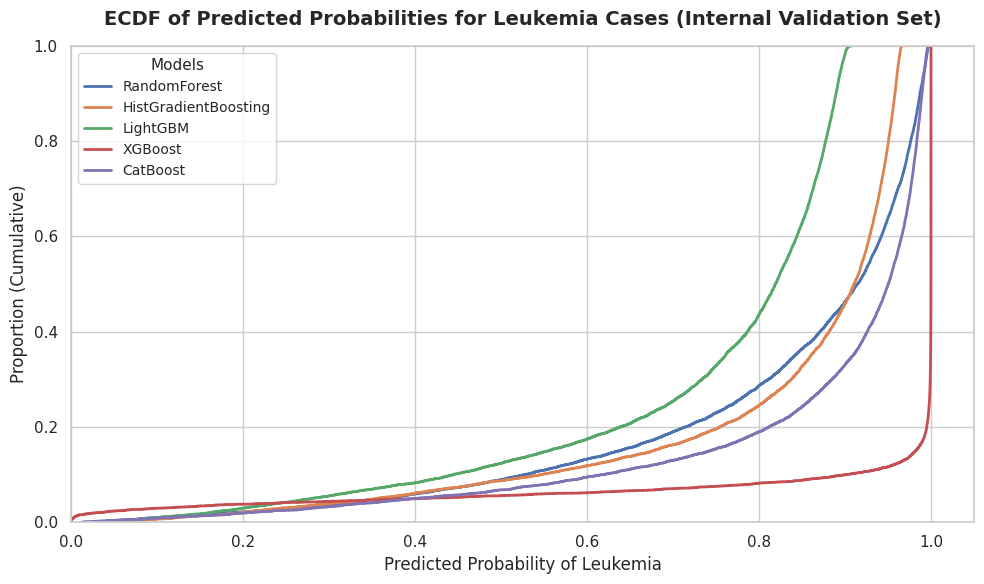

In [51]:
# Extract internal validation features and true targets
X_val_int = datasets["val_int"]["X"]
y_val_int = datasets["val_int"]["y"]

# Filter features to keep only true leukemia samples (class label = 1)
leukemia_mask = (y_val_int == 1)
X_val_int_leukemia = X_val_int[leukemia_mask]

plt.figure(figsize=(10, 6))
sea.set_theme(style="whitegrid")

# Fit models on training data and plot ECDF for each tuned model
for name, model in tuned_models.items():
    # Fit on training data first
    model.fit(X_train, y_train)

    # Predict probability of the positive class (leukemia)
    y_probs = model.predict_proba(X_val_int_leukemia)[:, 1]
    sea.ecdfplot(y_probs, label=name, linewidth=2)

plt.title("ECDF of Predicted Probabilities for Leukemia Cases (Internal Validation Set)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Predicted Probability of Leukemia", fontsize=12)
plt.ylabel("Proportion (Cumulative)", fontsize=12)
plt.xlim(0.0, 1.05)
plt.legend(title="Models", fontsize=10, title_fontsize=11)
plt.tight_layout()
plt.show()

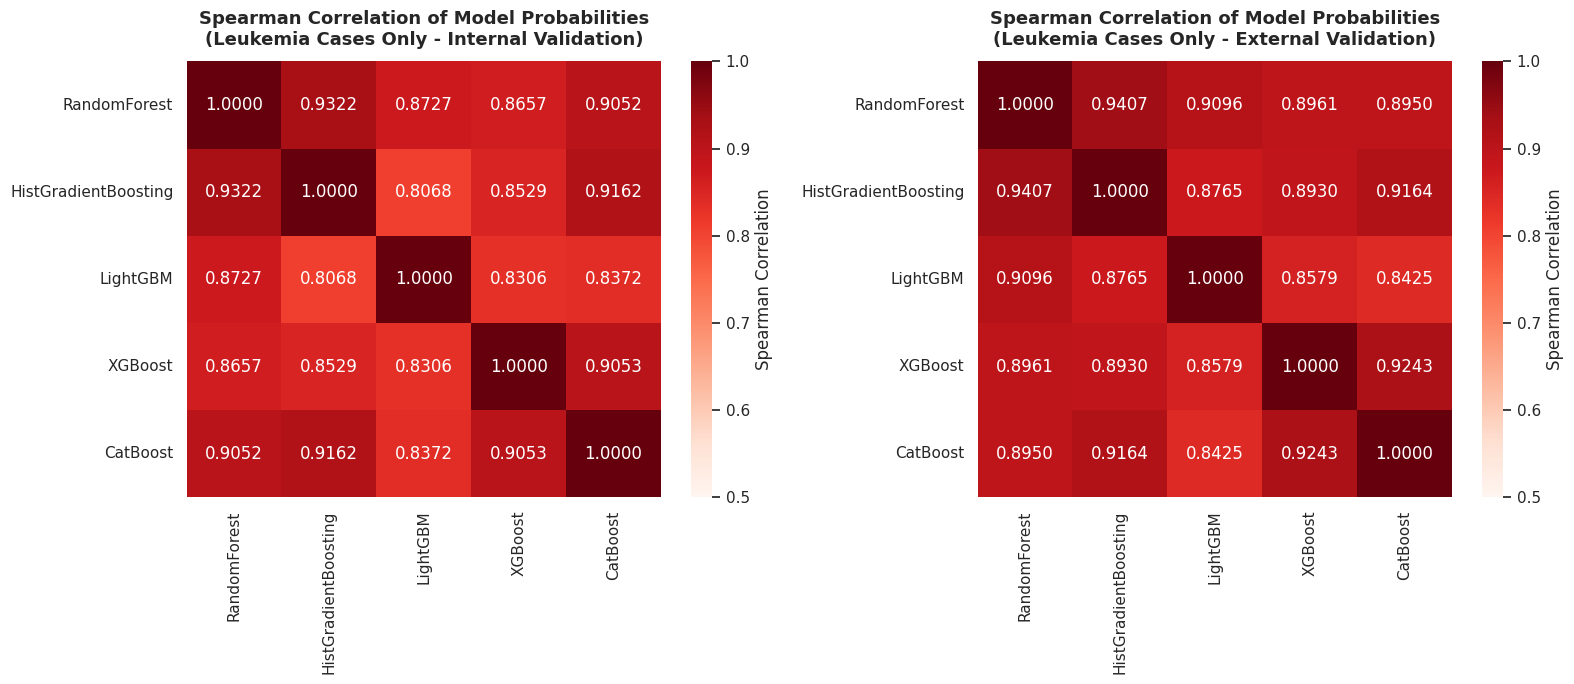

In [52]:
# Extract validation datasets
X_val_int = datasets["val_int"]["X"]
y_val_int = datasets["val_int"]["y"]

X_val_ext = datasets["val_ext"]["X"]
y_val_ext = datasets["val_ext"]["y"]

# Isolate leukemia samples (y == 1)
leukemia_mask_int = (y_val_int == 1)
leukemia_mask_ext = (y_val_ext == 1)

X_val_int_leukemia = X_val_int[leukemia_mask_int]
X_val_ext_leukemia = X_val_ext[leukemia_mask_ext]

# Collect probabilistic predictions from each tuned model for leukemia samples
probs_int = {}
probs_ext = {}

for name, model in tuned_models.items():
    probs_int[name] = model.predict_proba(X_val_int_leukemia)[:, 1]
    probs_ext[name] = model.predict_proba(X_val_ext_leukemia)[:, 1]

# Create DataFrames
df_probs_int = pd.DataFrame(probs_int)
df_probs_ext = pd.DataFrame(probs_ext)

# Calculate Spearman correlation matrices
corr_int = df_probs_int.corr(method="spearman")
corr_ext = df_probs_ext.corr(method="spearman")

# Plot the heatmaps side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Internal Validation Heatmap
sea.heatmap(
    corr_int,
    annot=True,
    cmap="Reds",
    fmt=".4f",
    vmin=0.5,
    vmax=1.0,
    ax=axes[0],
    cbar_kws={'label': 'Spearman Correlation'}
)
axes[0].set_title("Spearman Correlation of Model Probabilities\n(Leukemia Cases Only - Internal Validation)", fontsize=13, fontweight="bold", pad=12)

# External Validation Heatmap
sea.heatmap(
    corr_ext,
    annot=True,
    cmap="Reds",
    fmt=".4f",
    vmin=0.5,
    vmax=1.0,
    ax=axes[1],
    cbar_kws={'label': 'Spearman Correlation'}
)
axes[1].set_title("Spearman Correlation of Model Probabilities\n(Leukemia Cases Only - External Validation)", fontsize=13, fontweight="bold", pad=12)

plt.tight_layout()
plt.show()

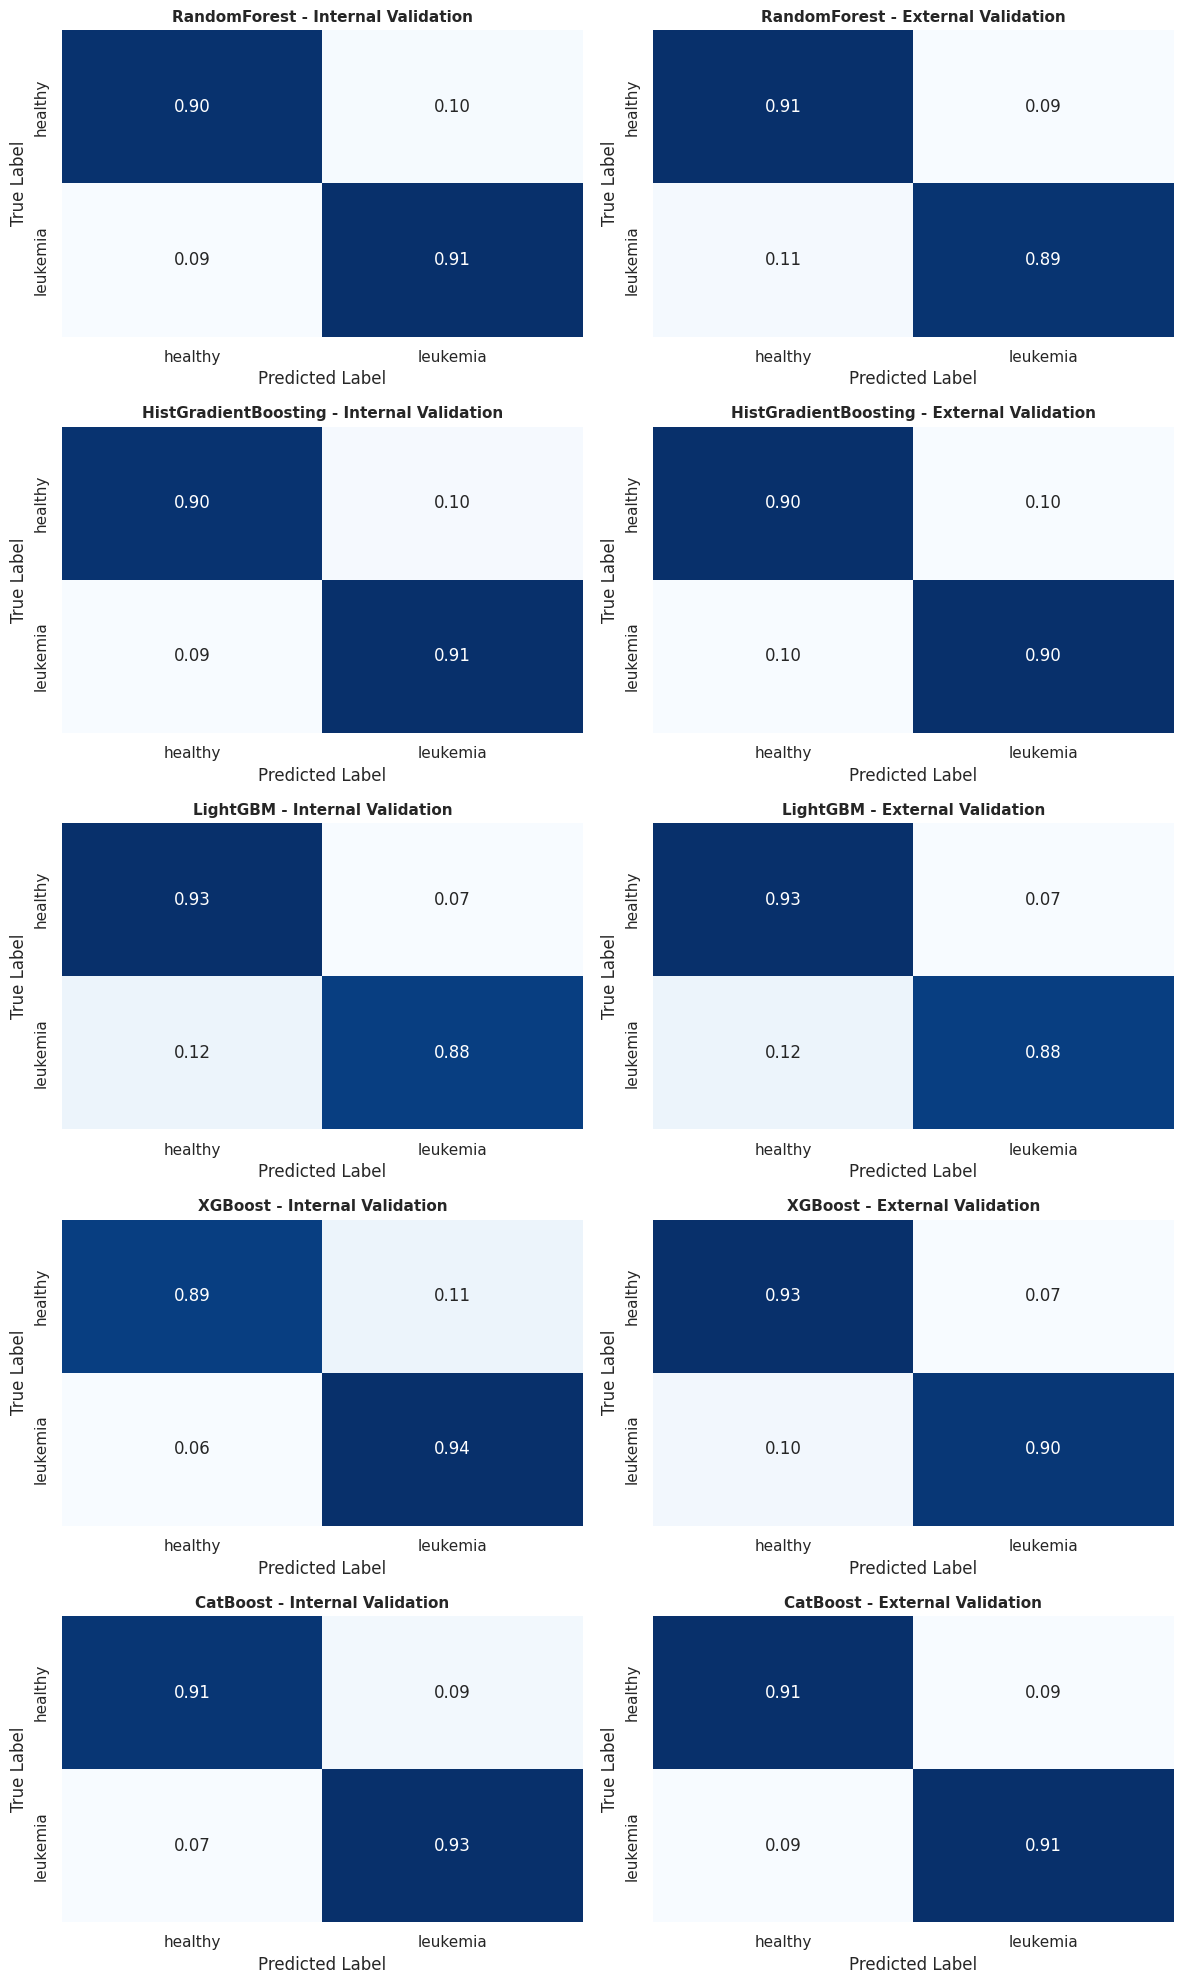

In [53]:
# Datasets to evaluate
X_val_int = datasets["val_int"]["X"]
y_val_int = datasets["val_int"]["y"]

X_val_ext = datasets["val_ext"]["X"]
y_val_ext = datasets["val_ext"]["y"]

# Classes mapping for visualization
labels = ["healthy", "leukemia"]

# Set up a grid with 5 rows (one for each model) and 2 columns (Internal & External)
fig, axes = plt.subplots(nrows=len(tuned_models), ncols=2, figsize=(12, 4 * len(tuned_models)))

for i, (name, model) in enumerate(tuned_models.items()):
    # Generate predictions
    y_pred_int = model.predict(X_val_int)
    y_pred_ext = model.predict(X_val_ext)

    # Compute confusion matrices
    cm_int = confusion_matrix(y_val_int, y_pred_int, normalize="true", labels=[0, 1])
    cm_ext = confusion_matrix(y_val_ext, y_pred_ext, normalize="true", labels=[0, 1])

    # Plot Internal Validation Heatmap
    ax_int = axes[i, 0]
    sea.heatmap(
        cm_int,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=ax_int,
        cbar=False
    )
    ax_int.set_title(f"{name} - Internal Validation", fontsize=11, fontweight="bold")
    ax_int.set_xlabel("Predicted Label")
    ax_int.set_ylabel("True Label")

    # Plot External Validation Heatmap
    ax_ext = axes[i, 1]
    sea.heatmap(
        cm_ext,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=ax_ext,
        cbar=False
    )
    ax_ext.set_title(f"{name} - External Validation", fontsize=11, fontweight="bold")
    ax_ext.set_xlabel("Predicted Label")
    ax_ext.set_ylabel("True Label")

plt.tight_layout()
plt.show()

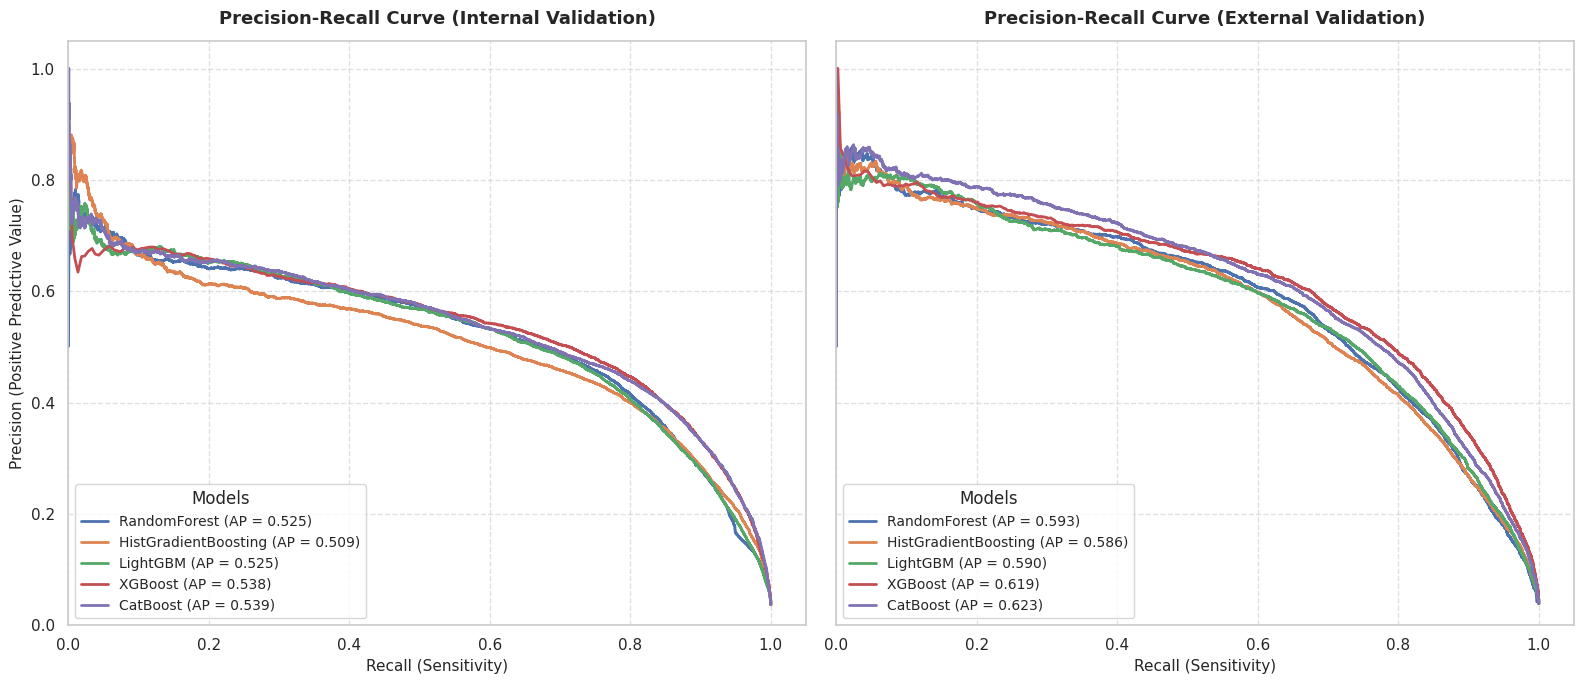

In [54]:
from sklearn.metrics import precision_recall_curve

# Extract datasets
X_val_int = datasets["val_int"]["X"]
y_val_int = datasets["val_int"]["y"]

X_val_ext = datasets["val_ext"]["X"]
y_val_ext = datasets["val_ext"]["y"]

# Plot setup
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

for name, model in tuned_models.items():
    # Get probabilities for positive class (leukemia)
    y_prob_int = model.predict_proba(X_val_int)[:, 1]
    y_prob_ext = model.predict_proba(X_val_ext)[:, 1]

    # Calculate Precision-Recall curves
    precision_int, recall_int, _ = precision_recall_curve(y_val_int, y_prob_int)
    precision_ext, recall_ext, _ = precision_recall_curve(y_val_ext, y_prob_ext)

    # Calculate average precision
    ap_int = average_precision_score(y_val_int, y_prob_int)
    ap_ext = average_precision_score(y_val_ext, y_prob_ext)

    # Plot Internal Validation Curve
    axes[0].plot(recall_int, precision_int, label=f"{name} (AP = {ap_int:.3f})", lw=2)

    # Plot External Validation Curve
    axes[1].plot(recall_ext, precision_ext, label=f"{name} (AP = {ap_ext:.3f})", lw=2)

# Formatting Internal Validation Plot
axes[0].set_title("Precision-Recall Curve (Internal Validation)", fontsize=13, fontweight="bold", pad=12)
axes[0].set_xlabel("Recall (Sensitivity)", fontsize=11)
axes[0].set_ylabel("Precision (Positive Predictive Value)", fontsize=11)
axes[0].set_xlim([0.0, 1.05])
axes[0].set_ylim([0.0, 1.05])
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend(title="Models", fontsize=10, loc="lower left")

# Formatting External Validation Plot
axes[1].set_title("Precision-Recall Curve (External Validation)", fontsize=13, fontweight="bold", pad=12)
axes[1].set_xlabel("Recall (Sensitivity)", fontsize=11)
axes[1].set_xlim([0.0, 1.05])
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend(title="Models", fontsize=10, loc="lower left")

plt.tight_layout()
plt.show()

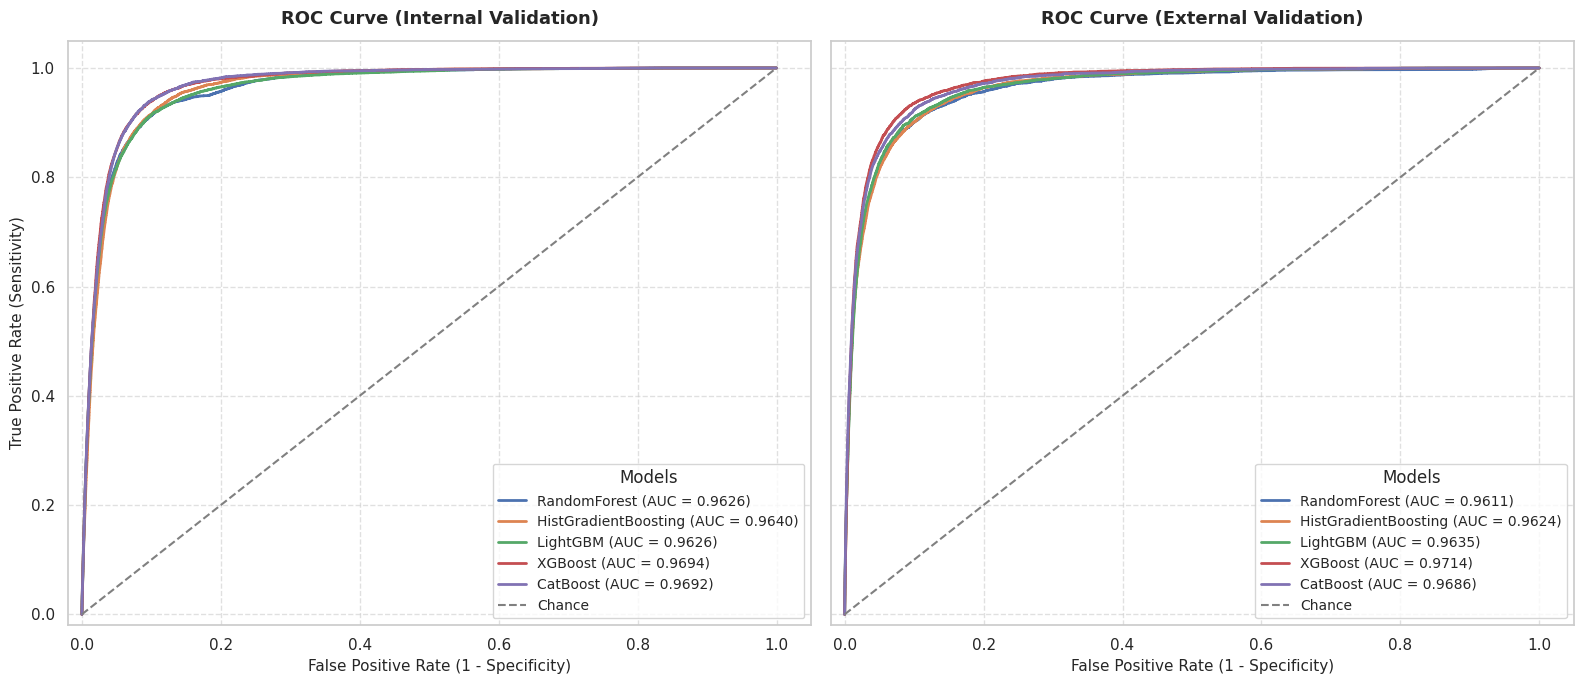

In [55]:
from sklearn.metrics import roc_curve, auc

# Extract datasets
X_val_int = datasets["val_int"]["X"]
y_val_int = datasets["val_int"]["y"]

X_val_ext = datasets["val_ext"]["X"]
y_val_ext = datasets["val_ext"]["y"]

# Plot setup
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

for name, model in tuned_models.items():
    # Get probabilities for positive class (leukemia)
    y_prob_int = model.predict_proba(X_val_int)[:, 1]
    y_prob_ext = model.predict_proba(X_val_ext)[:, 1]

    # Calculate ROC curves and AUC
    fpr_int, tpr_int, _ = roc_curve(y_val_int, y_prob_int)
    roc_auc_int = auc(fpr_int, tpr_int)

    fpr_ext, tpr_ext, _ = roc_curve(y_val_ext, y_prob_ext)
    roc_auc_ext = auc(fpr_ext, tpr_ext)

    # Plot Internal Validation Curve
    axes[0].plot(fpr_int, tpr_int, label=f"{name} (AUC = {roc_auc_int:.4f})", lw=2)

    # Plot External Validation Curve
    axes[1].plot(fpr_ext, tpr_ext, label=f"{name} (AUC = {roc_auc_ext:.4f})", lw=2)

# Formatting Internal Validation Plot
axes[0].plot([0, 1], [0, 1], color="grey", linestyle="--", lw=1.5, label="Chance")
axes[0].set_title("ROC Curve (Internal Validation)", fontsize=13, fontweight="bold", pad=12)
axes[0].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
axes[0].set_ylabel("True Positive Rate (Sensitivity)", fontsize=11)
axes[0].set_xlim([-0.02, 1.05])
axes[0].set_ylim([-0.02, 1.05])
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend(title="Models", fontsize=10, loc="lower right")

# Formatting External Validation Plot
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--", lw=1.5, label="Chance")
axes[1].set_title("ROC Curve (External Validation)", fontsize=13, fontweight="bold", pad=12)
axes[1].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
axes[1].set_xlim([-0.02, 1.05])
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend(title="Models", fontsize=10, loc="lower right")

plt.tight_layout()
plt.show()

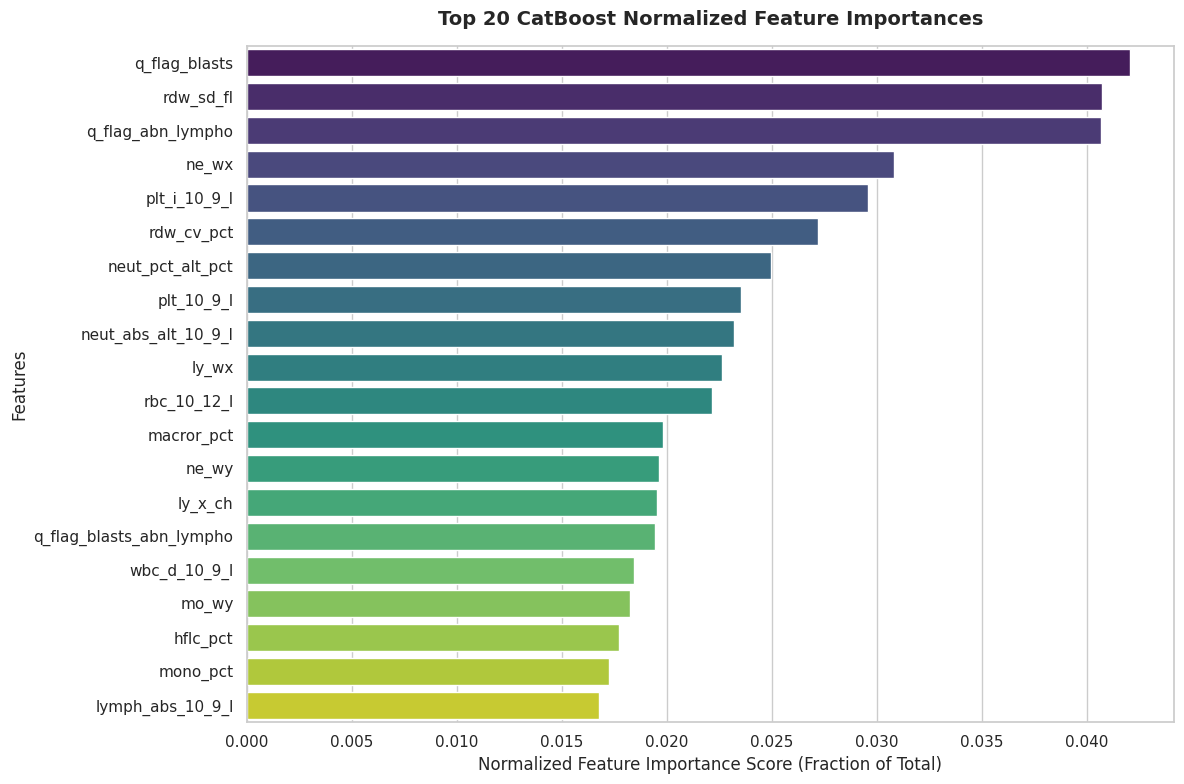

In [56]:
# Retrieve the fitted CatBoost model
catboost_model = tuned_models["CatBoost"]

# Calculate feature importances and pair them with feature names
importances = catboost_model.get_feature_importance()
feature_names = datasets["train"]["X"].columns

# Normalize importances so they sum to 1.0
normalized_importances = importances / importances.sum()

# Create a DataFrame and sort from highest to lowest
fi_df = pd.DataFrame({
    "feature": feature_names,
    "importance": normalized_importances
}).sort_values(by="importance", ascending=False)

# Take the top 20 features
top_20_fi = fi_df.head(20)

# Plot the feature importances
plt.figure(figsize=(12, 8))
sea.set_theme(style="whitegrid")

sea.barplot(
    x="importance",
    y="feature",
    data=top_20_fi,
    palette="viridis",
    hue="feature",
    legend=False
)

plt.title("Top 20 CatBoost Normalized Feature Importances", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Normalized Feature Importance Score (Fraction of Total)", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.tight_layout()
plt.show()

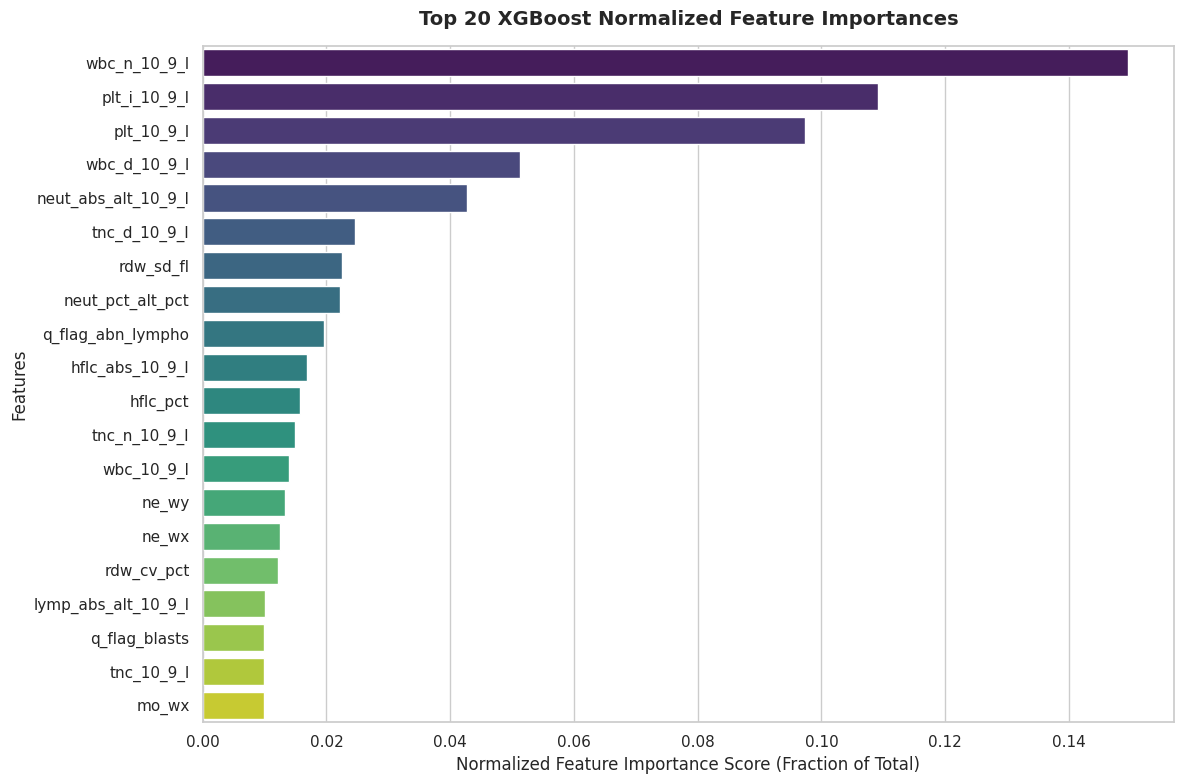

In [57]:
# Retrieve the fitted XGBoost model
xgb_model = tuned_models["XGBoost"]

# Calculate feature importances and pair them with feature names
importances = xgb_model.feature_importances_
feature_names = datasets["train"]["X"].columns

# Normalize importances so they sum to 1.0
normalized_importances = importances / importances.sum()

# Create a DataFrame and sort from highest to lowest
fi_df = pd.DataFrame({
    "feature": feature_names,
    "importance": normalized_importances
}).sort_values(by="importance", ascending=False)

# Take the top 20 features
top_20_fi = fi_df.head(20)

# Plot the feature importances
plt.figure(figsize=(12, 8))
sea.set_theme(style="whitegrid")

sea.barplot(
    x="importance",
    y="feature",
    data=top_20_fi,
    palette="viridis",
    hue="feature",
    legend=False
)

plt.title("Top 20 XGBoost Normalized Feature Importances", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Normalized Feature Importance Score (Fraction of Total)", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.tight_layout()
plt.show()

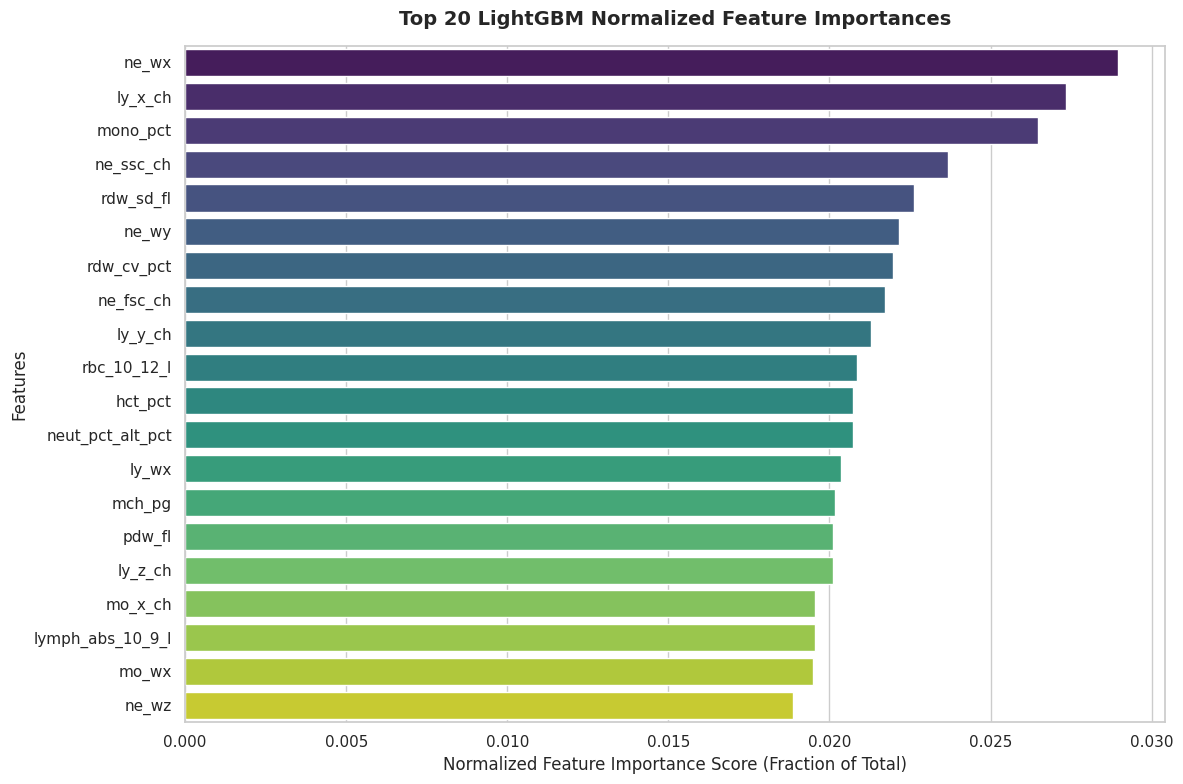

In [58]:
# Retrieve the fitted LightGBM model
lgb_model = tuned_models["LightGBM"]

# Calculate feature importances and pair them with feature names
importances = lgb_model.feature_importances_
feature_names = datasets["train"]["X"].columns

# Normalize importances so they sum to 1.0
normalized_importances = importances / importances.sum()

# Create a DataFrame and sort from highest to lowest
fi_df = pd.DataFrame({
    "feature": feature_names,
    "importance": normalized_importances
}).sort_values(by="importance", ascending=False)

# Take the top 20 features
top_20_fi = fi_df.head(20)

# Plot the feature importances
plt.figure(figsize=(12, 8))
sea.set_theme(style="whitegrid")

sea.barplot(
    x="importance",
    y="feature",
    data=top_20_fi,
    palette="viridis",
    hue="feature",
    legend=False
)

plt.title("Top 20 LightGBM Normalized Feature Importances", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Normalized Feature Importance Score (Fraction of Total)", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.tight_layout()
plt.show()

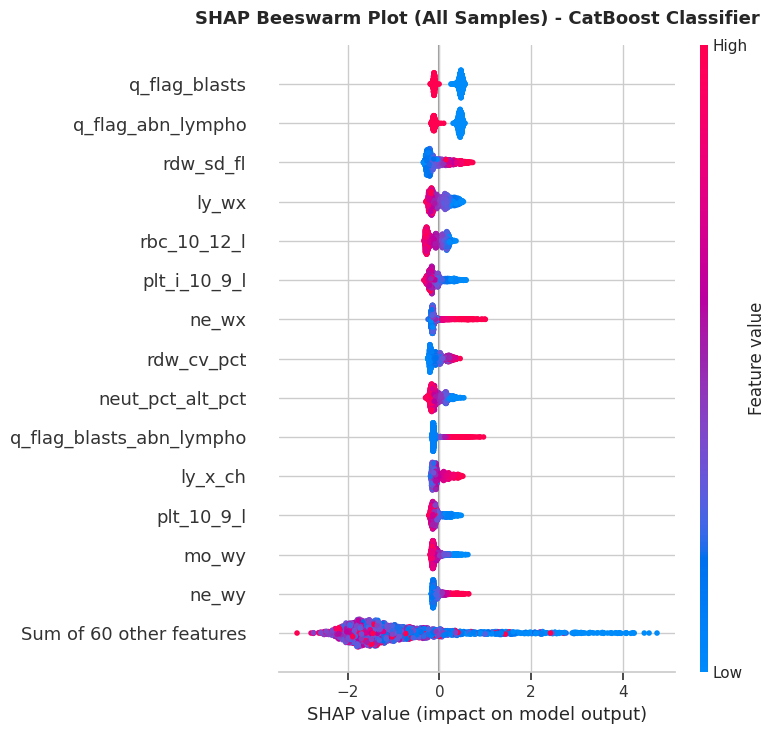

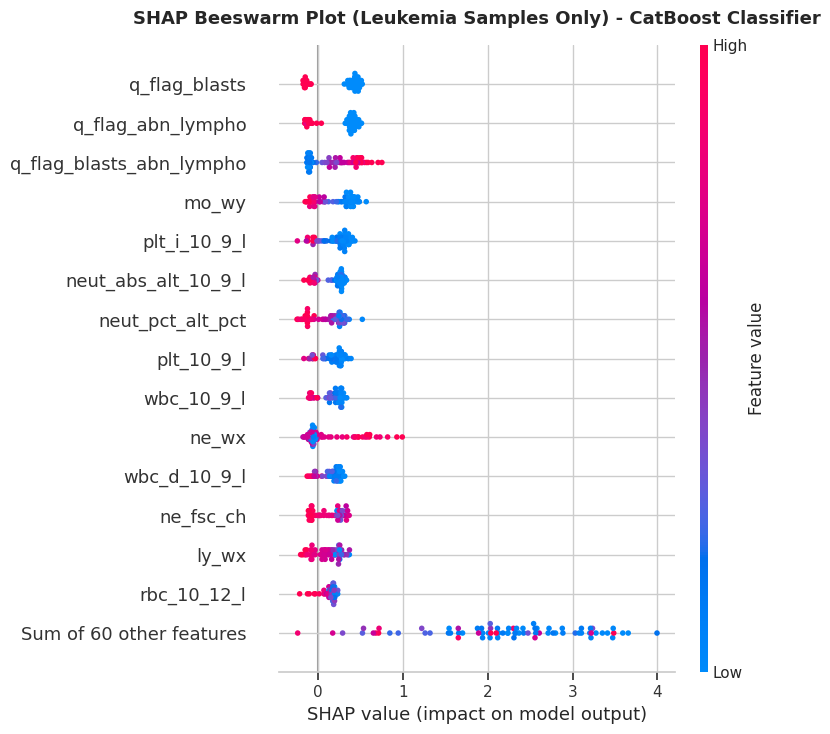

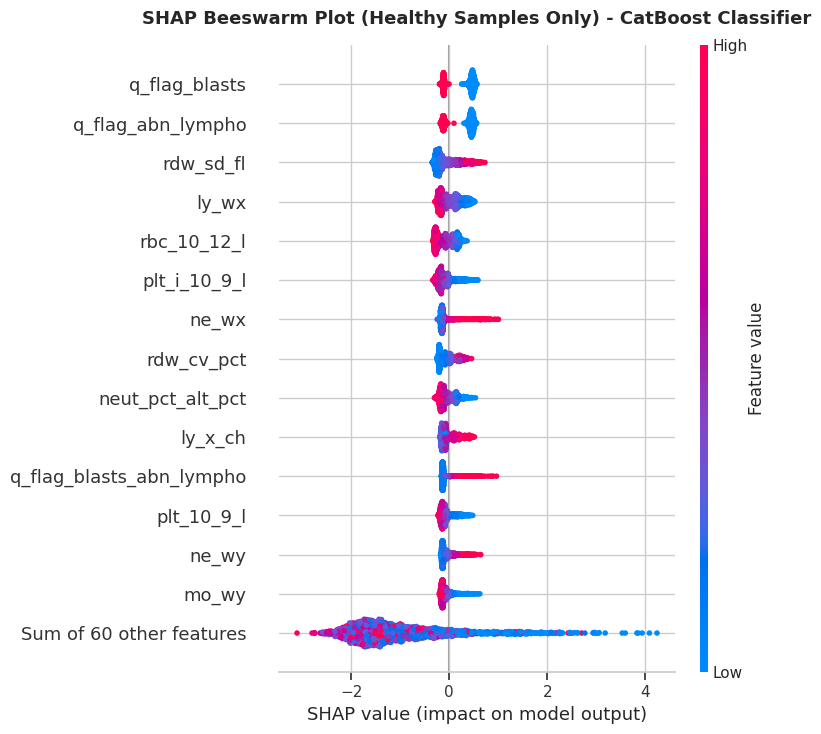

In [59]:
# Retrieve the fitted CatBoost model
catboost_model = tuned_models["CatBoost"]

# Prepare the datasets
X_val_int = datasets["val_int"]["X"]
y_val_int = datasets["val_int"]["y"]

# Sample for efficient SHAP calculation
sample_indices = X_val_int.sample(n=2000, random_state=SEED).index
X_sample = X_val_int.loc[sample_indices]
y_sample = y_val_int.loc[sample_indices]

# Compute SHAP values
explainer = shap.TreeExplainer(catboost_model)
shap_values = explainer(X_sample)

# 1. SHAP Beeswarm Plot: All Samples
plt.figure(figsize=(12, 6))
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP Beeswarm Plot (All Samples) - CatBoost Classifier", fontsize=13, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

# 2. SHAP Beeswarm Plot: Leukemia Samples Only (y == 1)
leukemia_mask = (y_sample == 1).values
if leukemia_mask.sum() > 0:
    plt.figure(figsize=(12, 6))
    shap.plots.beeswarm(shap_values[leukemia_mask], max_display=15, show=False)
    plt.title("SHAP Beeswarm Plot (Leukemia Samples Only) - CatBoost Classifier", fontsize=13, fontweight="bold", pad=15)
    plt.tight_layout()
    plt.show()
else:
    print("No leukemia samples found in the random subset for SHAP plotting.")

# 3. SHAP Beeswarm Plot: Healthy Samples Only (y == 0)
healthy_mask = (y_sample == 0).values
if healthy_mask.sum() > 0:
    plt.figure(figsize=(12, 6))
    shap.plots.beeswarm(shap_values[healthy_mask], max_display=15, show=False)
    plt.title("SHAP Beeswarm Plot (Healthy Samples Only) - CatBoost Classifier", fontsize=13, fontweight="bold", pad=15)
    plt.tight_layout()
    plt.show()
else:
    print("No healthy samples found in the random subset for SHAP plotting.")

<Figure size 1000x500 with 0 Axes>

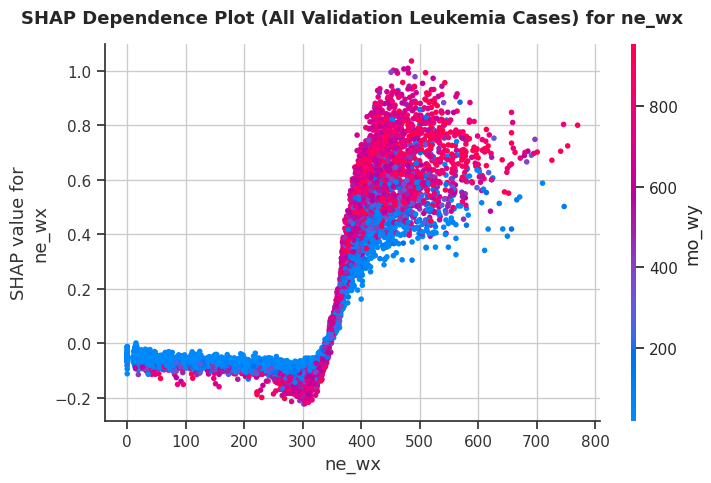

<Figure size 1000x500 with 0 Axes>

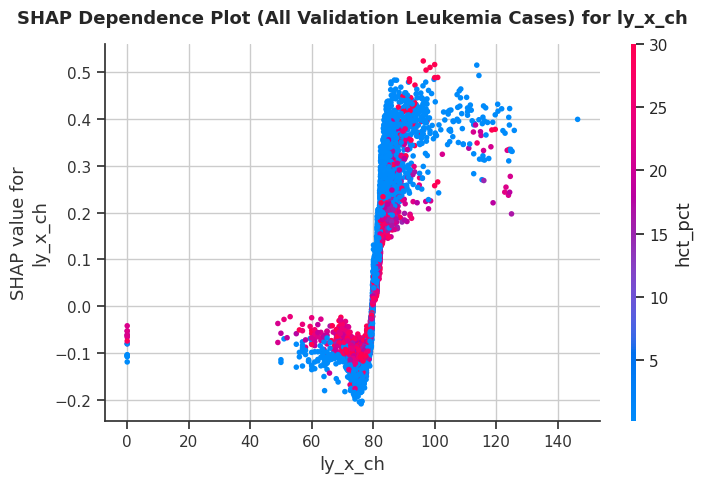

<Figure size 1000x500 with 0 Axes>

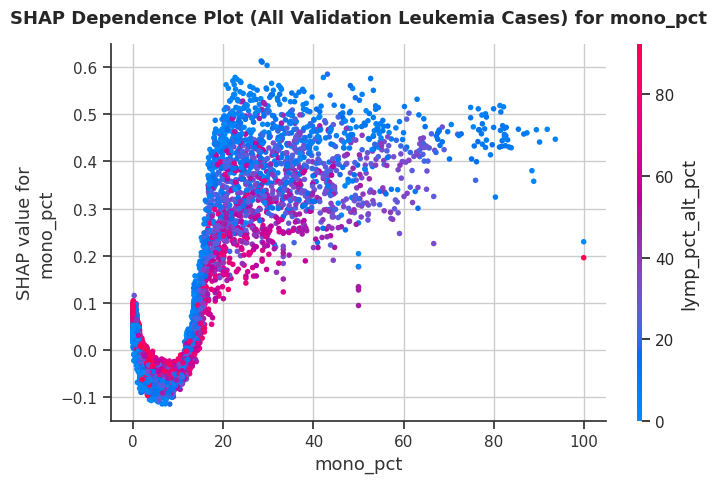

<Figure size 1000x500 with 0 Axes>

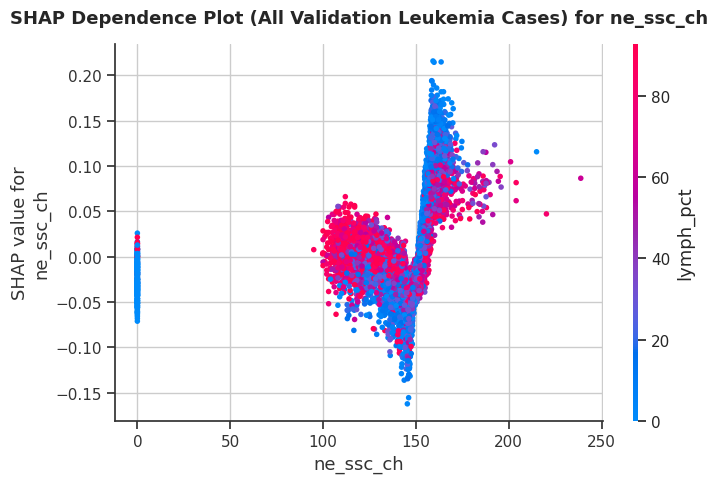

<Figure size 1000x500 with 0 Axes>

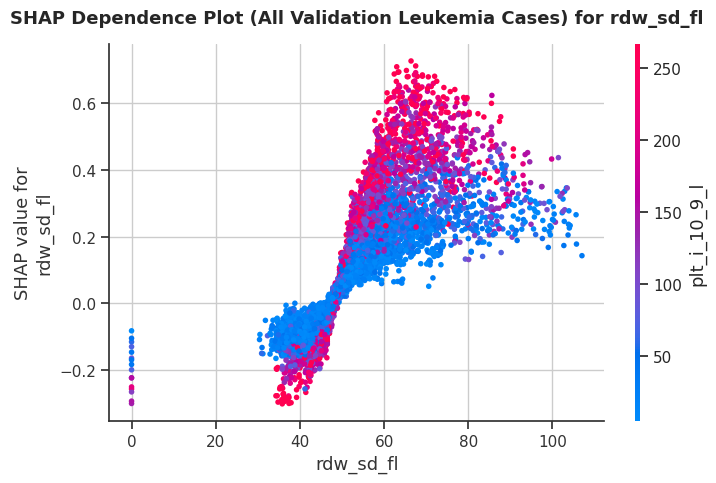

<Figure size 1000x500 with 0 Axes>

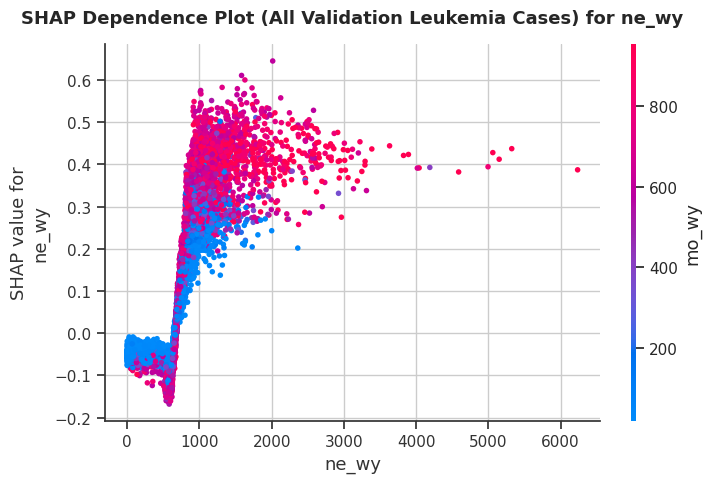

<Figure size 1000x500 with 0 Axes>

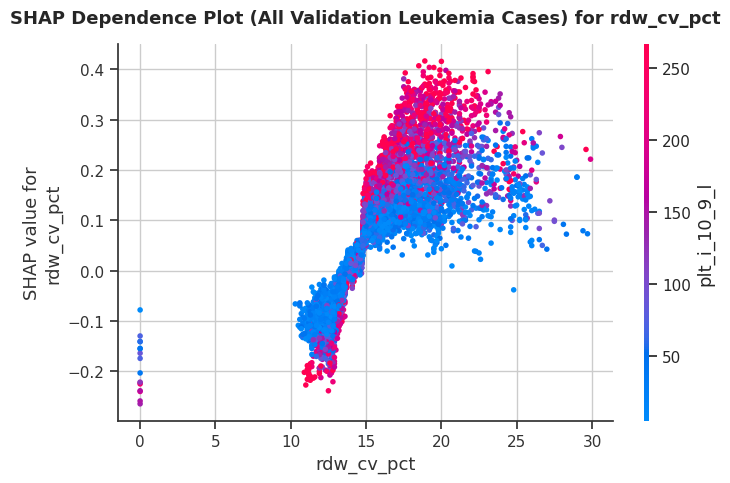

<Figure size 1000x500 with 0 Axes>

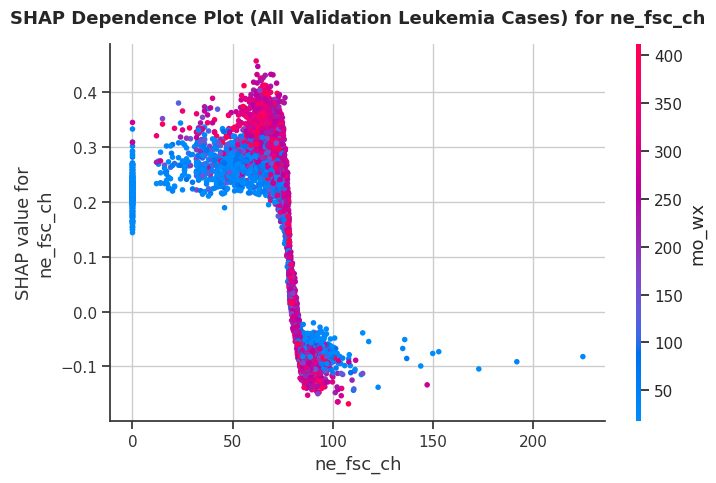

<Figure size 1000x500 with 0 Axes>

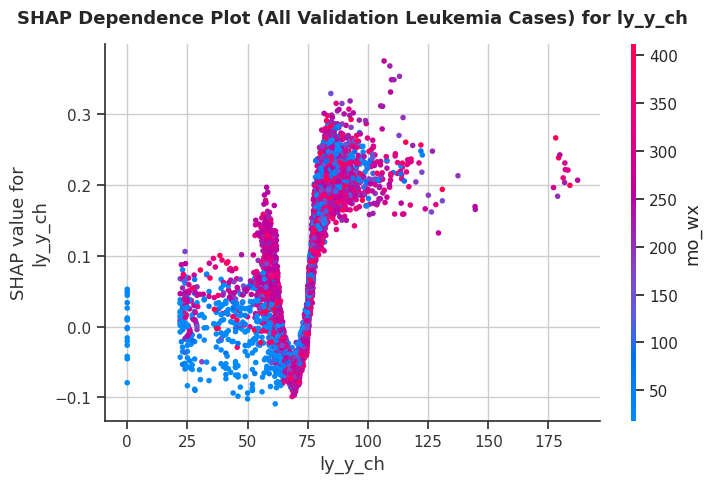

<Figure size 1000x500 with 0 Axes>

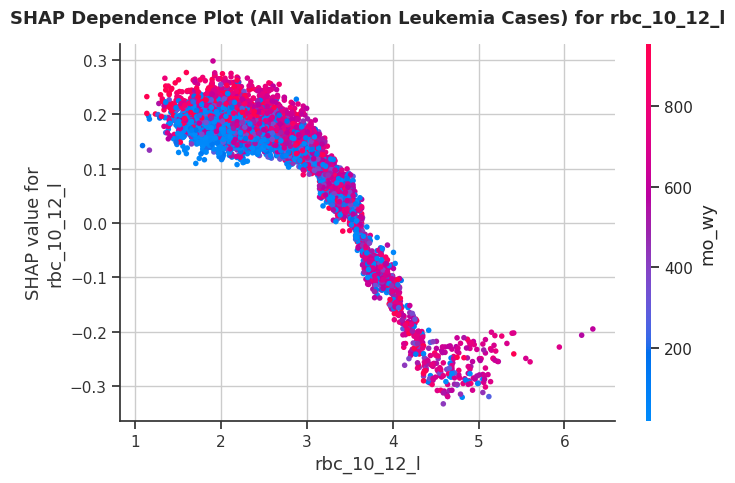

<Figure size 1000x500 with 0 Axes>

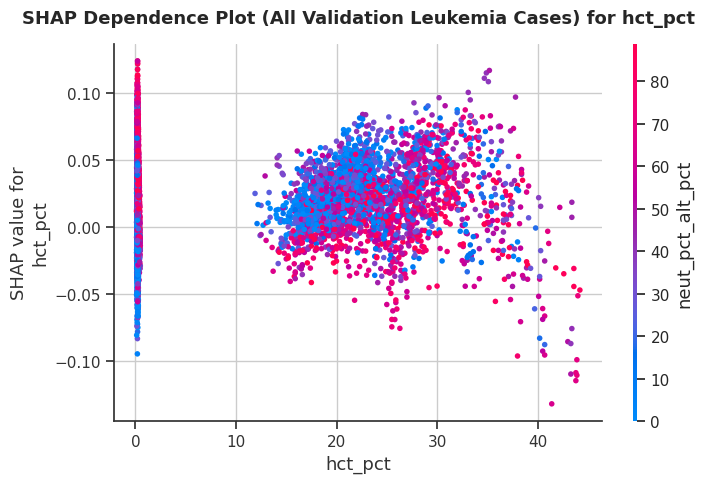

<Figure size 1000x500 with 0 Axes>

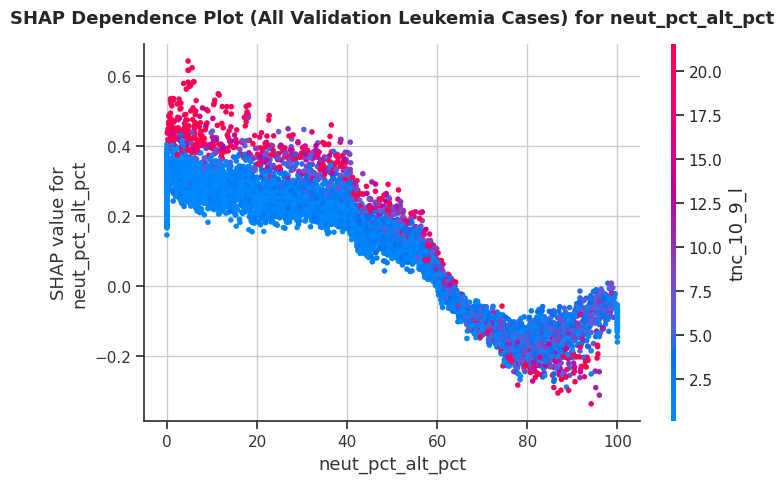

<Figure size 1000x500 with 0 Axes>

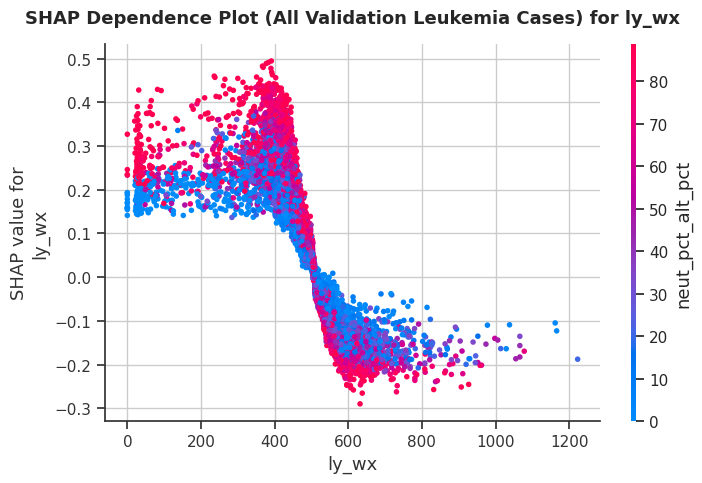

<Figure size 1000x500 with 0 Axes>

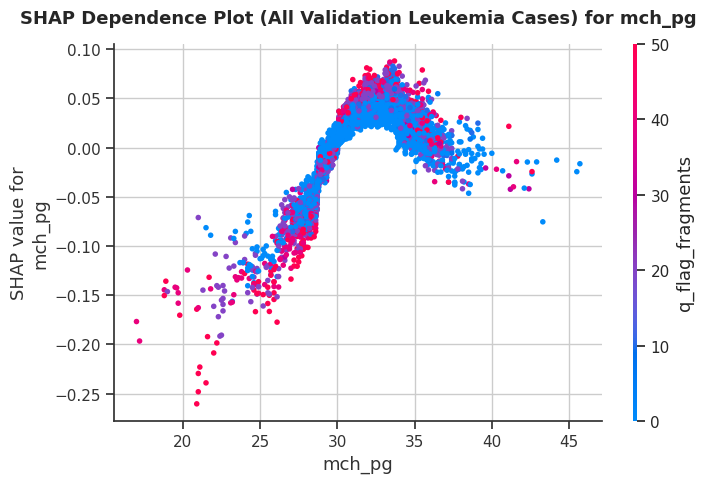

<Figure size 1000x500 with 0 Axes>

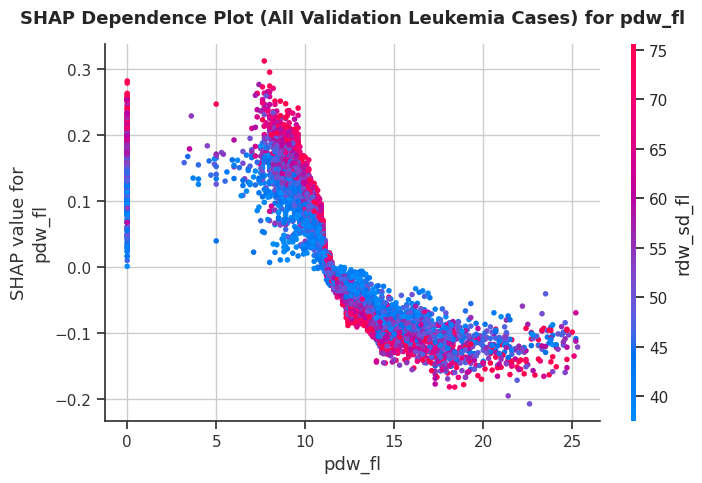

<Figure size 1000x500 with 0 Axes>

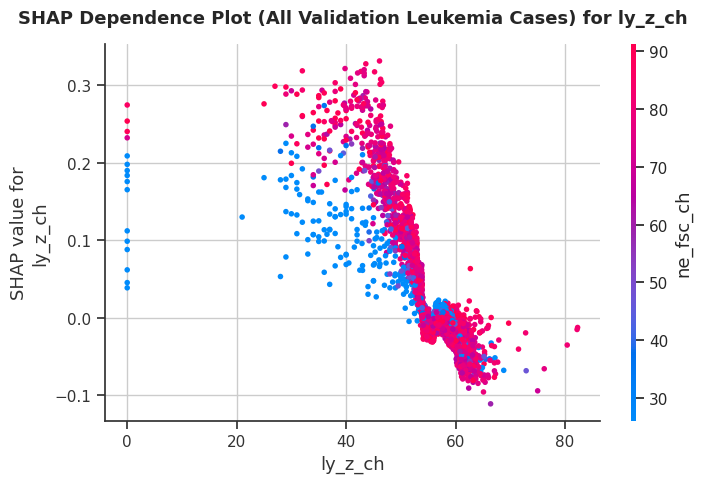

<Figure size 1000x500 with 0 Axes>

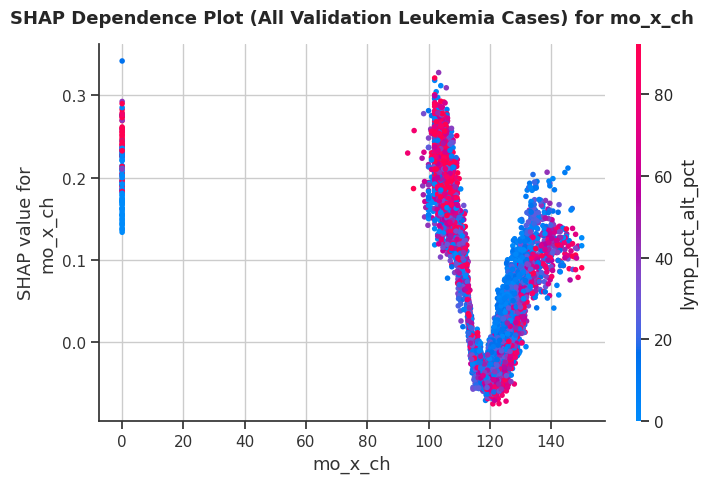

<Figure size 1000x500 with 0 Axes>

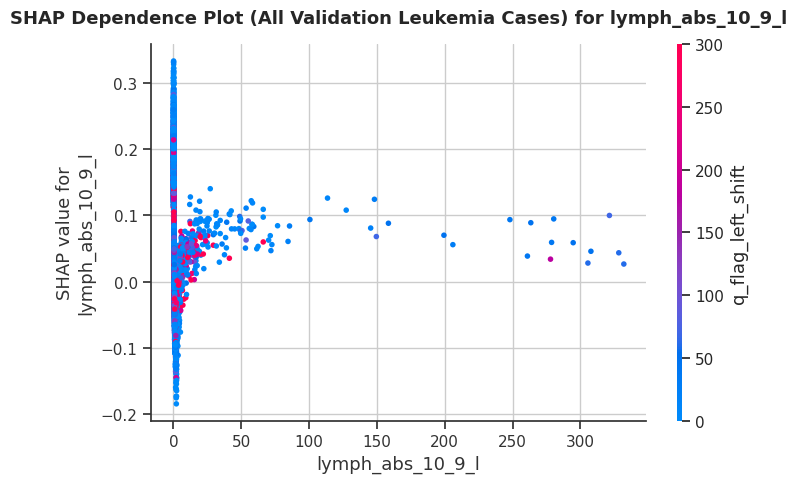

<Figure size 1000x500 with 0 Axes>

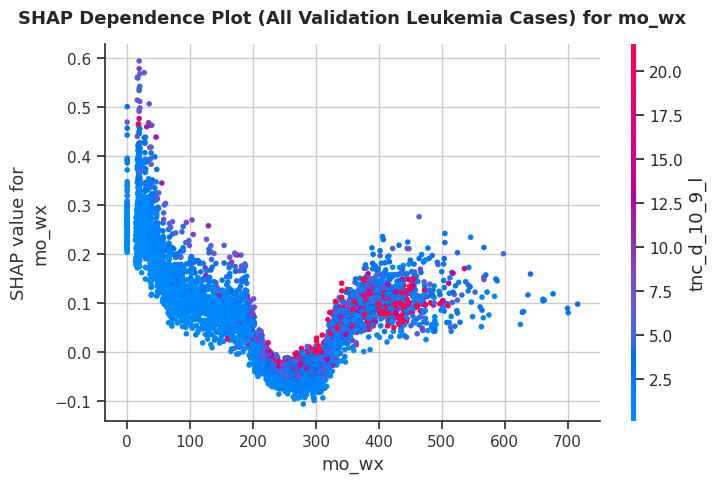

<Figure size 1000x500 with 0 Axes>

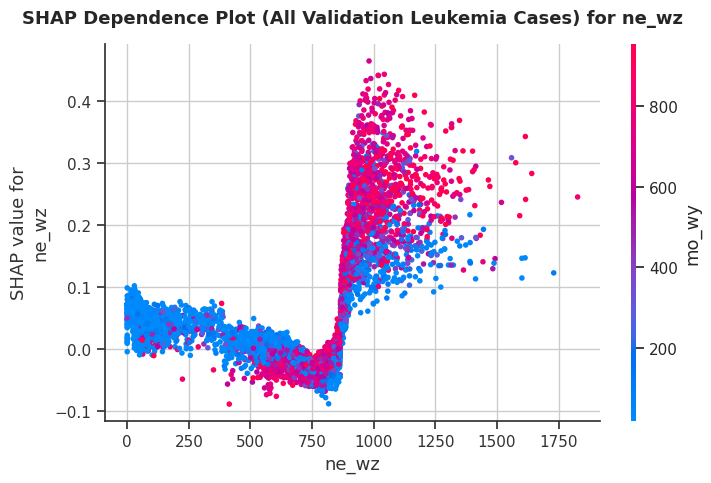

In [60]:
# Retrieve the fitted CatBoost model
catboost_model = tuned_models["CatBoost"]

# Extract all leukemia samples from the entire X_val_int
leukemia_mask_all = (y_val_int == 1)
X_val_int_leukemia = X_val_int[leukemia_mask_all]

# Compute SHAP values for all leukemia validation samples
explainer_all = shap.TreeExplainer(catboost_model)
shap_values_all_leukemia = explainer_all(X_val_int_leukemia)

top_20_features = list(top_20_fi["feature"])

for feature in top_20_features:
    if feature in X_val_int_leukemia.columns:
        plt.figure(figsize=(10, 5))
        # Generate dependence plot with automatic interaction indexing on all leukemia validation samples
        shap.dependence_plot(
            feature,
            shap_values_all_leukemia.values,
            X_val_int_leukemia,
            interaction_index="auto",
            show=False
        )
        plt.title(f"SHAP Dependence Plot (All Validation Leukemia Cases) for {feature}", fontsize=13, fontweight="bold", pad=15)
        plt.tight_layout()
        plt.show()
    else:
        print(f"Feature {feature} not found in dataset.")

In [67]:
# Retrieve unique sites in external validation data
val_ext_full = val_external
sites = val_ext_full["site"].unique().to_list()

# Prepare features and labels for Training
X_train = datasets["train"]["X"]
y_train = datasets["train"]["y"]

# Initialize and train our tuned models on training set
fitted_models = {}
for name, model in tuned_models.items():
    m = clone(model)
    m.fit(X_train, y_train)
    fitted_models[name] = m

site_results = []

# Evaluate performance for each site in val_external
for site in sorted(sites):
    # Filter data for this specific site
    site_df = val_ext_full.filter(pl.col("site") == site)

    # Get features and target
    X_site = site_df.select(pl.exclude(["leukemia_label", "site"])).to_pandas()
    y_site = site_df["leukemia_label"].to_pandas()

    # Compute positive class prevalence
    prevalence = y_site.mean()
    total_samples = len(y_site)
    leuk_samples = int(y_site.sum())

    # Run evaluation for each model
    for name, model in fitted_models.items():
        y_prob = model.predict_proba(X_site)[:, 1]
        ap_score = average_precision_score(y_site, y_prob)

        site_results.append({
            "Site": site,
            "Total Samples": total_samples,
            "Leukemia Cases": leuk_samples,
            "Prevalence": f"{prevalence:.2%}",
            "Model": name,
            "Average Precision": ap_score
        })

# Convert results to a DataFrame and pivot/display
site_results_df = pd.DataFrame(site_results)

# Generate a pivot table showing Average Precision across models and sites
pivot_ap = site_results_df.pivot(index="Model", columns="Site", values="Average Precision")
print("Leukemia Classification Performance (Average Precision) by Site on val_ext:\n")
display(pivot_ap.style.highlight_max(color="lightgreen", axis=0).format("{:.4f}"))

Leukemia Classification Performance (Average Precision) by Site on val_ext:



Site,D,E,F,G
Model,,,,
CatBoost,0.5837,0.6496,0.5916,0.7364
HistGradientBoosting,0.5503,0.6135,0.5695,0.7049
LightGBM,0.5432,0.6014,0.5769,0.7288
RandomForest,0.5647,0.6055,0.5642,0.7142
XGBoost,0.5433,0.6592,0.5675,0.7390


---
# 6. Evaluating Ensembles
#### Stand-alone CatBoostClassifier displays the strongest performance


In [68]:
from scipy.stats import rankdata

# Prepare features and true targets
X_val_int = datasets["val_int"]["X"]
y_val_int = datasets["val_int"]["y"]
X_val_ext = datasets["val_ext"]["X"]
y_val_ext = datasets["val_ext"]["y"]

# 1. Get predicted probabilities from all tuned models
probs_int = {}
probs_ext = {}

for name, model in fitted_models.items():
    probs_int[name] = model.predict_proba(X_val_int)[:, 1]
    probs_ext[name] = model.predict_proba(X_val_ext)[:, 1]

# 2. Build several ensemble strategies

# Strategy A: Simple Mean of all 5 models
mean_all_int = np.mean([probs_int[m] for m in probs_int], axis=0)
mean_all_ext = np.mean([probs_ext[m] for m in probs_ext], axis=0)

# Strategy B: Rank Average of all 5 models (helps scale predictions with different calibrations)
rank_all_int = np.mean([rankdata(probs_int[m]) / len(probs_int[m]) for m in probs_int], axis=0)
rank_all_ext = np.mean([rankdata(probs_ext[m]) / len(probs_ext[m]) for m in probs_ext], axis=0)

# Strategy C: Top 3 Best Single Models (CatBoost, XGBoost, LightGBM) Mean
top3_models = ["CatBoost", "XGBoost", "LightGBM"]
mean_top3_int = np.mean([probs_int[m] for m in top3_models], axis=0)
mean_top3_ext = np.mean([probs_ext[m] for m in top3_models], axis=0)

# 3. Compile and compare results
ensemble_results = []

# Individual models
for name in fitted_models.keys():
    ensemble_results.append({
        "Model/Ensemble": name,
        "Val Int AP": average_precision_score(y_val_int, probs_int[name]),
        "Val Ext AP": average_precision_score(y_val_ext, probs_ext[name])
    })

# Ensemble candidates
ensemble_results.append({
    "Model/Ensemble": "Ensemble (Mean of All 5)",
    "Val Int AP": average_precision_score(y_val_int, mean_all_int),
    "Val Ext AP": average_precision_score(y_val_ext, mean_all_ext)
})
ensemble_results.append({
    "Model/Ensemble": "Ensemble (Rank Avg of All 5)",
    "Val Int AP": average_precision_score(y_val_int, rank_all_int),
    "Val Ext AP": average_precision_score(y_val_ext, rank_all_ext)
})
ensemble_results.append({
    "Model/Ensemble": "Ensemble (Mean of Top 3: CatBoost/XGB/LGB)",
    "Val Int AP": average_precision_score(y_val_int, mean_top3_int),
    "Val Ext AP": average_precision_score(y_val_ext, mean_top3_ext)
})

# Display summary comparison table
comparison_df = pd.DataFrame(ensemble_results).sort_values(by="Val Ext AP", ascending=False)
print("Model and Ensemble Comparison (Sorted by External Validation Average Precision):")
display(comparison_df.style.highlight_max(subset=["Val Int AP", "Val Ext AP"], color="lightgreen").format({"Val Int AP": "{:.5f}", "Val Ext AP": "{:.5f}"}))


Model and Ensemble Comparison (Sorted by External Validation Average Precision):


,Model/Ensemble,Val Int AP,Val Ext AP
4,CatBoost,0.53918,0.62271
7,Ensemble (Mean of Top 3: CatBoost/XGB/LGB),0.54752,0.62158
3,XGBoost,0.53820,0.61923
6,Ensemble (Rank Avg of All 5),0.54602,0.61819
5,Ensemble (Mean of All 5),0.54345,0.61469
0,RandomForest,0.52531,0.59250
2,LightGBM,0.52474,0.58958
1,HistGradientBoosting,0.50919,0.58630


In [69]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from sklearn.metrics import average_precision_score

# 1. Extract true targets and model names
y_val_int = datasets["val_int"]["y"].values
y_val_ext = datasets["val_ext"]["y"].values
model_names = list(fitted_models.keys())

# 2. Collect probabilities matrices (N_samples x M_models)
# We'll use the already-computed probs_int and probs_ext from the previous cell
P_int = np.column_stack([probs_int[name] for name in model_names])
P_ext = np.column_stack([probs_ext[name] for name in model_names])

# 3. Define objective function to minimize (Negative Average Precision)
def objective(weights):
    # Normalize weights to sum to 1 inside objective for stability
    w = weights / np.sum(weights)
    blend_probs = np.dot(P_int, w)
    return -average_precision_score(y_val_int, blend_probs)

# 4. Define constraints and bounds (weights >= 0, sum(weights) = 1)
# We initialize with equal weights
init_weights = np.ones(len(model_names)) / len(model_names)
bounds = [(0, 1) for _ in range(len(model_names))]
constraints = {"type": "eq", "fun": lambda w: np.sum(w) - 1.0}

# Run optimizer
opt_res = minimize(
    objective,
    x0=init_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"maxiter": 500}
)

best_weights = opt_res.x / np.sum(opt_res.x)

# 5. Evaluate the optimized ensemble
blend_int_probs = np.dot(P_int, best_weights)
blend_ext_probs = np.dot(P_ext, best_weights)

opt_int_ap = average_precision_score(y_val_int, blend_int_probs)
opt_ext_ap = average_precision_score(y_val_ext, blend_ext_probs)

# 6. Build the summary dataframe
weight_df = pd.DataFrame({
    "Model": model_names,
    "Optimized Weight": best_weights
}).sort_values(by="Optimized Weight", ascending=False)

print("--- Optimized Ensemble Weights (Tuned on Internal Validation) ---")
display(weight_df.style.hide(axis="index").format({"Optimized Weight": "{:.4%}"}))

print(f"\nOptimized Ensemble Internal Validation AP: {opt_int_ap:.5f}")
print(f"Optimized Ensemble External Validation AP: {opt_ext_ap:.5f}")


--- Optimized Ensemble Weights (Tuned on Internal Validation) ---


Model,Optimized Weight
CatBoost,20.0257%
XGBoost,20.0257%
RandomForest,19.9828%
LightGBM,19.9828%
HistGradientBoosting,19.9828%



Optimized Ensemble Internal Validation AP: 0.54346
Optimized Ensemble External Validation AP: 0.61470


---
# 7. All Hyperparameters

In [61]:
rf_params = {
  ## Constants
  "random_state": SEED,
  "n_jobs": -1,
  ## Params
  "n_estimators": 364,
  "max_depth": 9,
  "min_samples_split":37,
  "min_samples_leaf": 22,
  "max_features":0.5402165506053076
}


histgb_params = {
    ## Constants
    "random_state": SEED,

    ## Optimized hyperparameters
    "learning_rate": 0.006764063066785397,
    "max_iter": 478,
    "max_depth": 5,
    "min_samples_leaf": 77,
    "max_features": 0.5226735720450432,
    "l2_regularization": 3.693047547433555
}


lgbm_params = {
    ## Constants
    #"metric": "average_precision",
    "random_state": SEED,
    "verbosity": -1,
    "n_jobs": -1,
    "n_estimators": 85,

    ## Optimized hyperparameters
    "learning_rate": 0.022391637805027266,
    "max_depth": 12,
    "min_child_samples": 22,
    "subsample_freq": 14,
    "subsample": 0.5184855697652336,
    "colsample_bytree": 0.7048956867789798,
    "reg_alpha": 1.751082593462855e-06,
    "reg_lambda": 0.05392466911928448,
    "num_leaves": 448
}


catboost_params = {
    ## Constants
    "random_seed": SEED,
    #"eval_metric": "PRAUC",
    "verbose": False,
    "thread_count": -1,
    "allow_writing_files": False,
    "iterations": 564,
    "bootstrap_type": "Bayesian",

    ## Optimized hyperparameters
    "learning_rate": 0.01676726864765657,
    "depth": 10,
    "l2_leaf_reg": 8.801622580284043,
    "random_strength": 9.93584384028874,
    "bagging_temperature": 0.13121632284419055,
    "rsm": 0.8001773914839359,
    "border_count": 237
}


xgb_params = {
    ## Constants
    "random_state": SEED,
    #"eval_metric": "aucpr",
    "verbosity": 0,
    "n_jobs": -1,
    "n_estimators": 878,

    ## Optimized hyperparameters
    "grow_policy": "depthwise",
    "learning_rate": 0.0370741662278796,
    "min_child_weight": 9.408768204956597e-08,
    "subsample": 0.5175892595091047,
    "colsample_bytree": 0.7905346057276204,
    "reg_alpha": 9.509180830004382e-07,
    "reg_lambda": 0.02220487406782116,
    "gamma": 1.1827967080615169e-05,
    "max_depth": 12
}